### Binary Saturation

This notebooks purpose is to simply do a sanity check on the analytical expressions found to describe the number of photons *lost* on an APD because of **binary saturation**. Quandelas software provides a plataform to simulate and use photonic quantum computers, implementing linear optics tools. The basics of *perceval*, their programming kit and a general description on how their computer works is described on another notebook *Perceval-Learning*. I will not delve deeper into this, in order to mantain the purpose of this notebook. However the gist of it is that they have quantum dot based single photon emmitters and can implement any unitary using a combination of beam-splitters and phase shifters. They also have Photon Number Resolving (PNR) detectors, which can also be set to work as an APD, by simply setting the threhsold of photons counted to 1. We can choose detector efficiencis and set many noise models to their circuits, which simulate our own setup.

---

**Problem Statement:** Suppose you have a photon detector of the Geiger-type (binary response click or no-click), such as an Avalanche Photon Diode (APD) detector, and a Photon Number Resolving (PNR) detector. While your source can send single photons and photons that come in pairs. Since APDs cannot count two photons, everytime a pair arrives we will count only one, underestimating the true number of photons - a problem we will call **binary saturation**. How can we make sure that even with an APD we can still recover the total number of photon arrivals?

---

This is a reasonable simplification of our real problem in Idor (which will be discussed further throught the notebook), however it does serve as an exercise in better understanding the problem we are dealing with and as a simple check on wheter or not the analytical expressions found work well even for this simple simulations.

The answer to our problem is: yes, there is a way to recover the lost photons due to binary saturation and we have a definite expression for it, which will be given later.


In [1]:
#!pip install perceval-quandela

In [2]:
# Perceval 1.3.0 is needed!!
import importlib.util, subprocess, sys

from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import perceval as pcvl
from perceval.simulators import Simulator
from perceval.backends import SLOSBackend

plt.rcParams.update({"figure.figsize": (6, 4), "font.size": 12,
                     "axes.grid": True, "grid.alpha": 0.3})
print("perceval", pcvl.__version__)

# Crisp plots on projectors and HiDPI screens (works on Colab too).
%config InlineBackend.figure_format = "retina"

perceval 1.3.0



One first experiment is simply to understand the average number of photons lost on APDs when comparing with PNR detectors:
$$
\Delta N = \langle N^{PNR}_{det}\rangle - \langle N^{APD}_{det}\rangle = \eta^2
$$

Where $\eta$ is the detector efficiency and we assume that $\eta^{PNR} = \eta^{APD}$. In this case we should be able to test it fairly simple, since we will have detectors of the same efficiency and we must simply impose on our PNR detector to work as an APD.

**Experiment:** One fiber connected to a PNR or to an APD. The light state which enters the fiber is $|2\rangle$ and we can tune the detector efficiencys to be $\eta \in [0,1]$. We expect to find the correct probabilities for detecting $P(0)$, $P(1)$ and (only for PNR) $P(2)$. From this we can calculate $\langle N \rangle = \sum_n n*P(n)$.


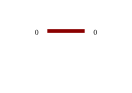

In [3]:
circuit = pcvl.Circuit(1)
pcvl.pdisplay(circuit)
# Circuit

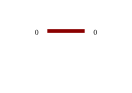

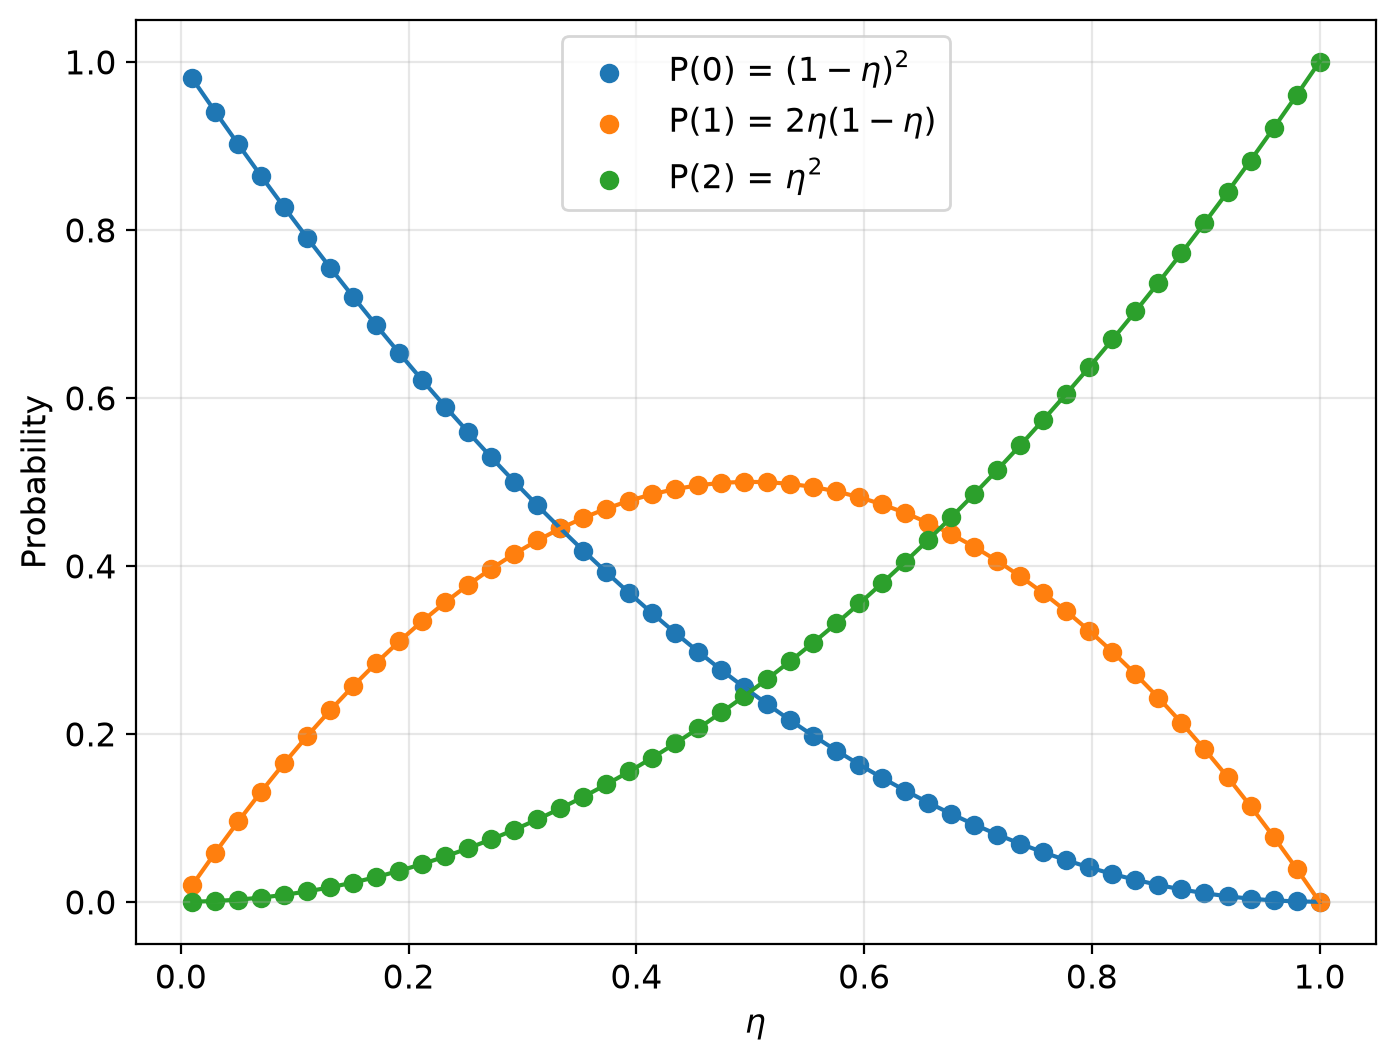

In [4]:

def simple():
    return pcvl.Circuit(1)

etas = np.linspace(0.01, 1, 50)


state = pcvl.BasicState('|2>')

result=[]
p0=[]
p1=[]
p2=[]

for eta in etas:
    proc = pcvl.Processor("SLOS", simple())
    detector = pcvl.Detector.pnr() # PNR
    detector.efficiency = eta # efficiency

    proc.add(0, detector)

    proc.with_input(state)
    proc.min_detected_photons_filter(0) ### detects at least 0 photons
    res = pcvl.algorithm.Sampler(proc).probs()['results']
    result.append(res)
    p0.append(res.get(pcvl.BasicState([0]), 0.0))
    p1.append(res.get(pcvl.BasicState([1]), 0.0))
    p2.append(res.get(pcvl.BasicState([2]), 0.0))

### Expected results:

p0_ = lambda x: (1-x)**2
p1_ = lambda x: 2*x*(1-x)
p2_ = lambda x: x**2


po_points = [p0_(eta) for eta in etas]
p1_points = [p1_(eta) for eta in etas]
p2_points = [p2_(eta) for eta in etas]


circuit = simple()
display(pcvl.pdisplay(circuit))

fig, (ax1) = plt.subplots(1,1, figsize=(8, 6))

ax1.scatter(etas, p0, label = r'P(0) = $(1-\eta)^2$')
ax1.scatter(etas, p1, label = r'P(1) = $2\eta(1 - \eta)$')
ax1.scatter(etas, p2, label = r'P(2) = $\eta^2$')

ax1.plot(etas, po_points)
ax1.plot(etas, p1_points)
ax1.plot(etas, p2_points)

ax1.set_xlabel(r'$\eta$')
ax1.set_ylabel(r'Probability')


plt.legend()
plt.show()

It works just as expected for the PNDs.

By setting a threshold to our detector we obtain an APD (or any Geiger-type detector).

In [5]:
from perceval.components import Detector
det = Detector.threshold()  #example!
N = 100
det.detect(N) #sent N photons but the detected state was 1

|1>

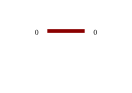

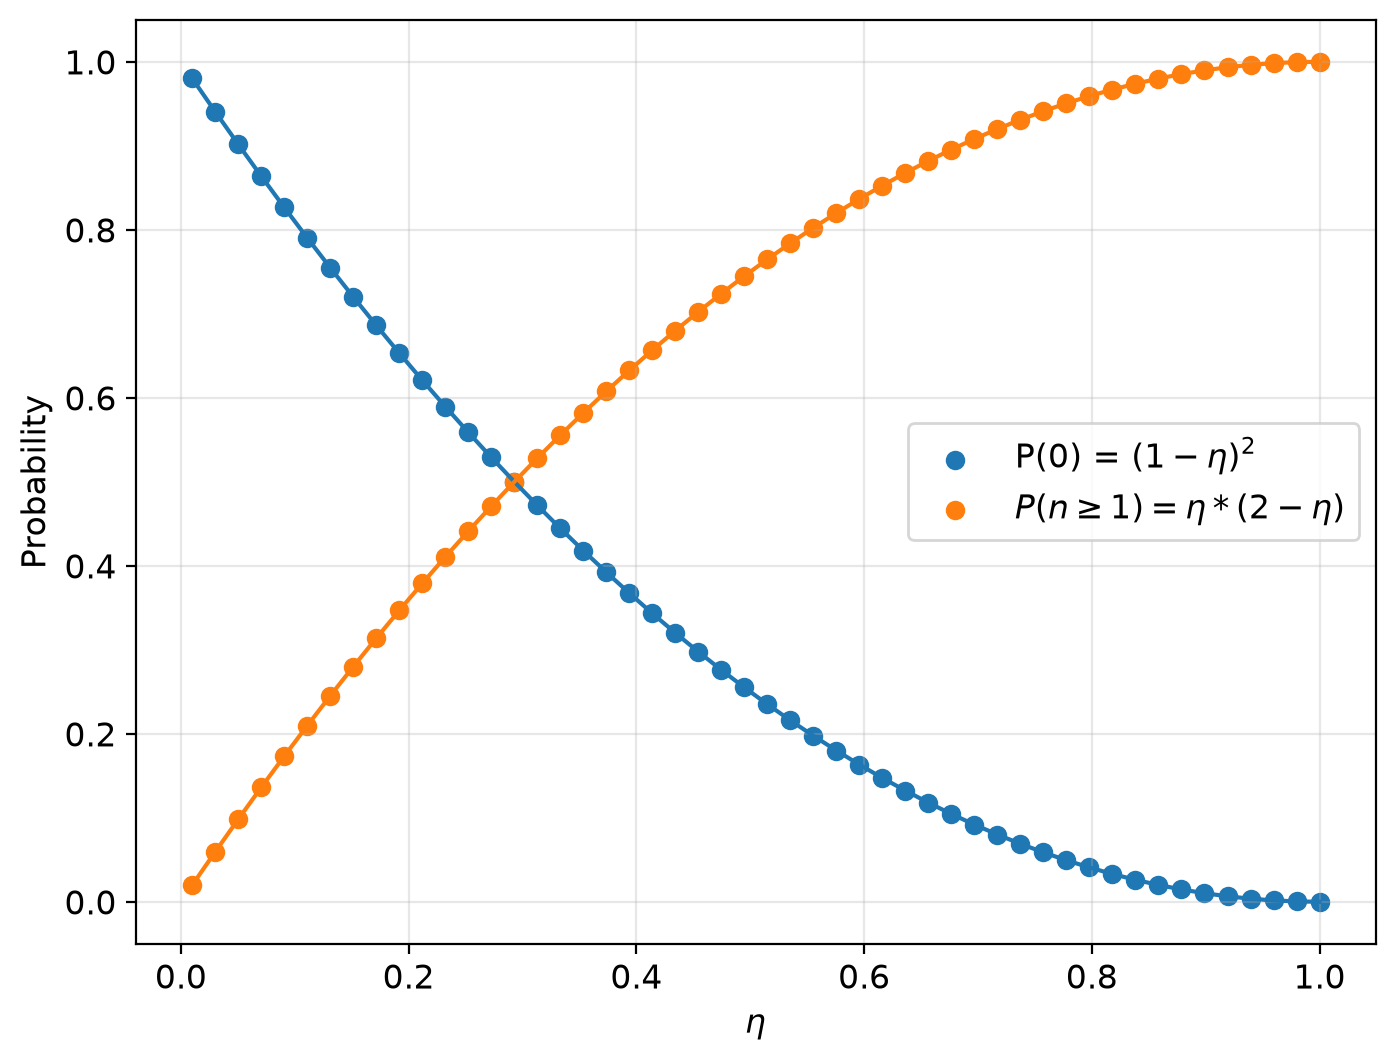

In [6]:

def simple():
    return pcvl.Circuit(1)

etas = np.linspace(0.01, 1, 50)


state = pcvl.BasicState('|2>')

result=[]
p0_APD=[]
p1_APD=[]


for eta in etas:
    proc = pcvl.Processor("SLOS", simple())


    proc.with_input(state)

    detector = pcvl.Detector.threshold() # PNR
    detector.efficiency = eta # efficiency
    proc.add(0, detector)

    proc.min_detected_photons_filter(0) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()['results']
    result.append(res)
    p0_APD.append(res.get(pcvl.BasicState([0]), 0.0))
    p1_APD.append(res.get(pcvl.BasicState([1]), 0.0))


### Expected results:

p0_ = lambda x: (1-x)**2
pgeq1 = lambda x: x*(2-x)

po_points = [p0_(eta) for eta in etas]
pgeq1_points = [pgeq1(eta) for eta in etas]



circuit = simple()
display(pcvl.pdisplay(circuit))

fig, (ax1) = plt.subplots(1,1, figsize=(8, 6))

ax1.scatter(etas, p0_APD, label = r'P(0) = $(1-\eta)^2$')
ax1.scatter(etas, p1_APD, label = r'$P(n \geq 1) = \eta*(2 - \eta)$')

plt.plot(etas, po_points)
plt.plot(etas, pgeq1_points)


ax1.set_xlabel(r'$\eta$')
ax1.set_ylabel(r'Probability')


plt.legend()
plt.show()

Now that we have both probability distributions we can calulate $\langle \Delta N \rangle$.

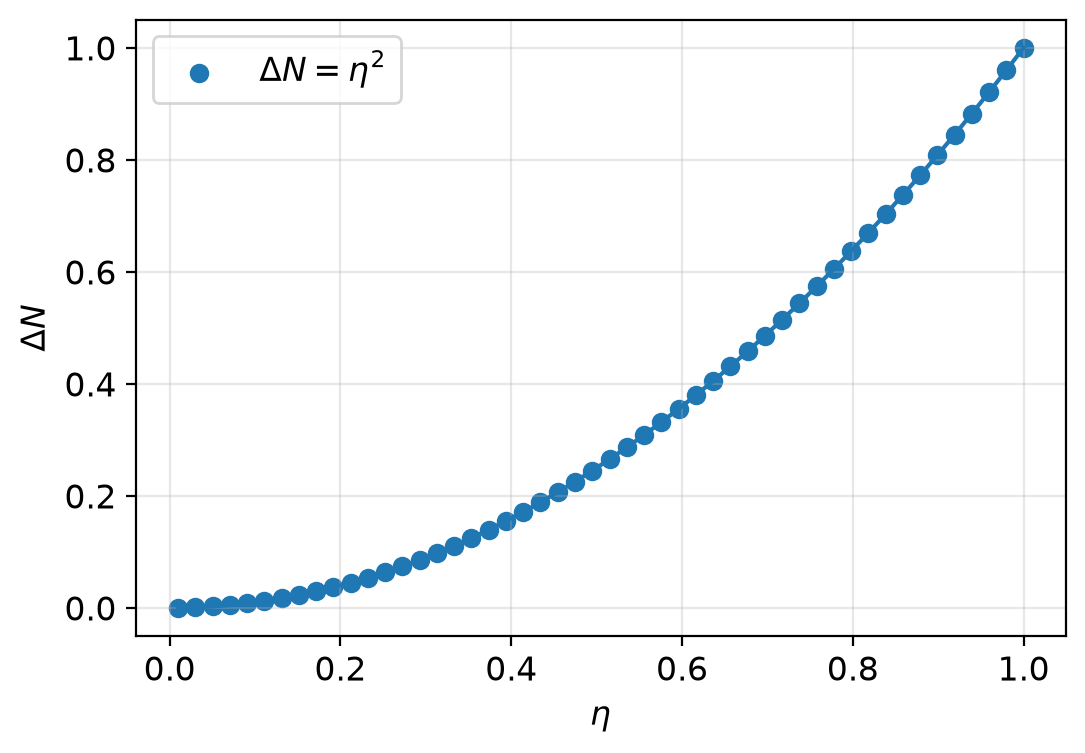

In [7]:
average_apd = np.array([ p0_APD[i]*0 + p1_APD[i]*1 for i in range(len(p0_APD))])
average_pnr = np.array([ p0[i]*0 + p1[i]*1 + p2[i]*2 for i in range(len(p0))])


avg_exp = lambda x : x**2

delta_N = average_pnr - average_apd


plt.scatter(etas, delta_N, label = r'$\Delta N = \eta^2$')
plt.plot(etas, [avg_exp(eta) for eta in etas])


plt.xlabel(r'$\eta$')
plt.ylabel(r'$\Delta N$')
plt.legend()
plt.show()

As seen above there is a clear relation between the number of photons which we measure with an APD when compared to a PNR. We still haven't found, however, a way to correct this discrepancy. This is the next step.

Now we will introduce another component in order to explore this problem further and get closer to the original discussions around the topic of binary saturation.

In our problem we will now have two fibers, although photons will enter only through one ($|2,0\rangle$ or $|0,2\rangle$), a beam splitter (BS) and two detectors, one in each possible path. Our problem now is that for a certain reflectivity of the BS the two incoming photons will both be sent through one path and, while PNRs will be able to distinguish them, we know that for APDs that will not happen. An advantage, however, is that now we will be able to count coincidences of the photon arrival. Since Perceval assumes that all generated photons are indistinguishable (although this can be altered!) for every $|1,1\rangle$ we count one coincidence. As we will see later on, our correction factor only has to do with the number of coincidences, detector efficiency and transmitance (reflexivity).

By changing the transmitance ($t = 1 - r$) of our BS we will be able to check if the correction holds up. But first, we will test how a PNR detector changes photon counts if we change the transmitance. We expect it to not change, since for this kind of detector it does not matter the number of photons arriving.

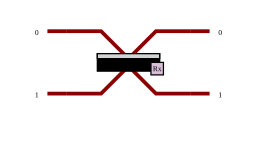

In [8]:
def coincidence(theta):
  return pcvl.Circuit(2)//pcvl.BS(theta = theta)

display(pcvl.pdisplay(coincidence(np.pi/2)))

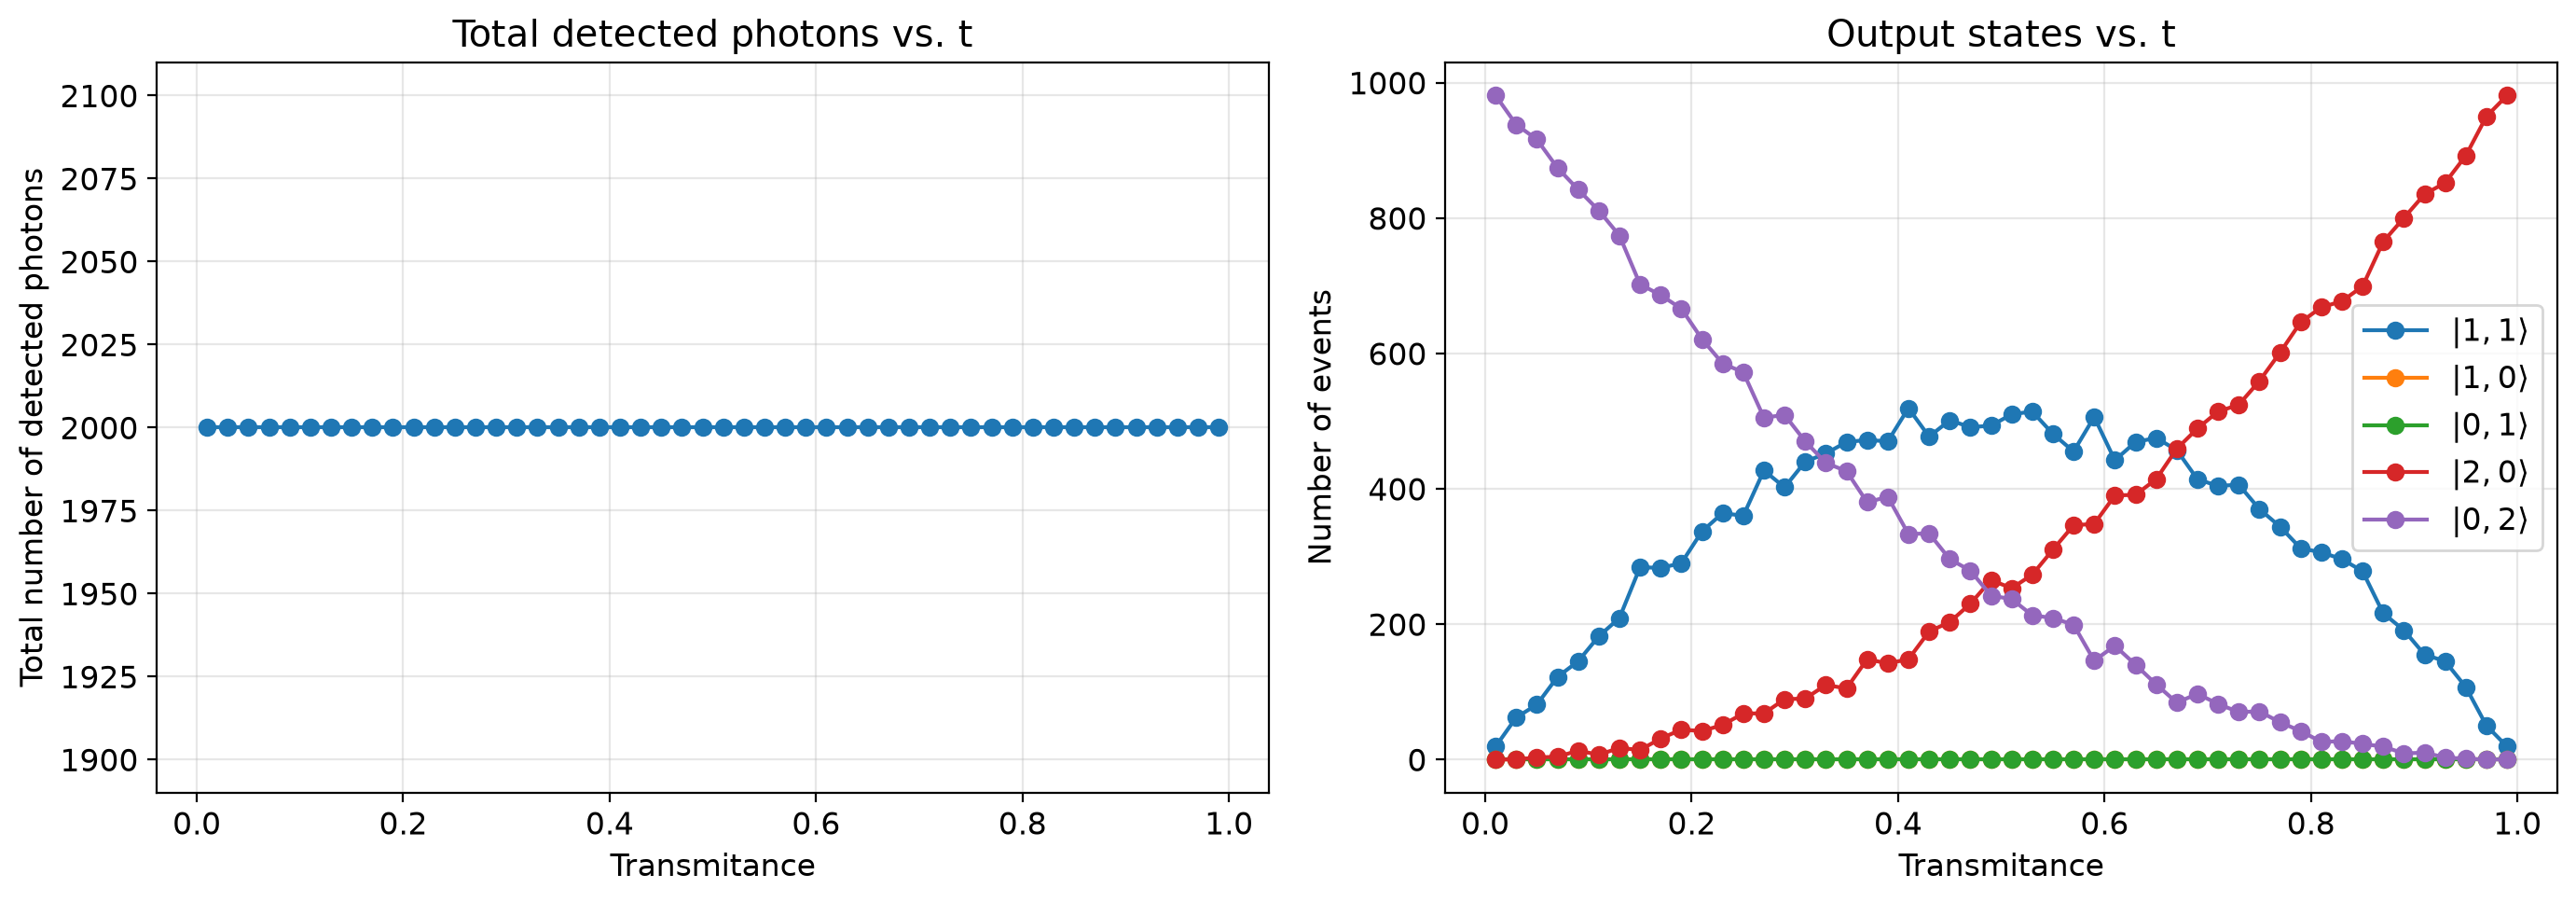

In [9]:
# Beam splitter defined from transmitance
def coincidence(r):
    return pcvl.Circuit(2) // pcvl.BS(pcvl.BS.r_to_theta(r))


# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Transmission
ts = 1 - rs

state = pcvl.BasicState('|2,0>')

result = []

n_samples = 1000

# Total number of detected photons for each theta
total_photons = []

for t in ts:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(t),
        noise=pcvl.NoiseModel(brightness=1)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0,
        '20': 0,
        '02': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

        elif sample == pcvl.BasicState('|2,0>'):
            counts['20'] += 1

        elif sample == pcvl.BasicState('|0,2>'):
            counts['02'] += 1

    result.append(counts)

    # Total number of detected photons for this theta
    N_photons = (
        counts['01']
        + counts['10']
        + 2*counts['11']
        + 2*counts['20']
        + 2*counts['02']
    )

    total_photons.append(N_photons)


# ---------------------------------------------------------
# Extract the individual counts
# ---------------------------------------------------------

n01 = [r['01'] for r in result]
n10 = [r['10'] for r in result]
n11 = [r['11'] for r in result]
n20 = [r['20'] for r in result]
n02 = [r['02'] for r in result]


# ---------------------------------------------------------
# Create two subplots
# ---------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Total number of photons
# ---------------------------------------------------------

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel(r'Transmitance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title('Total detected photons vs. t')

ax1.grid(True)


# ---------------------------------------------------------
# Plot 2: Individual output states
# ---------------------------------------------------------

ax2.plot(
    ts,
    n11,
    marker='o',
    label=r'$|1,1\rangle$'
)

ax2.plot(
    ts,
    n10,
    marker='o',
    label=r'$|1,0\rangle$'
)

ax2.plot(
    ts,
    n01,
    marker='o',
    label=r'$|0,1\rangle$'
)

ax2.plot(
    ts,
    n20,
    marker='o',
    label=r'$|2,0\rangle$'
)

ax2.plot(
    ts,
    n02,
    marker='o',
    label=r'$|0,2\rangle$'
)

ax2.set_xlabel(r'Transmitance')
ax2.set_ylabel('Number of events')
ax2.set_title('Output states vs. t')

ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()

As expected for the PNR the number of counts is always the same, eventhough the states change as we alter the transmitance. We also dont see states $|1,0\rangle$ and $|0,1\rangle$ because we assume there are no losses.


Now we would like to check how the same thing works for the APD.

We will plot the photon number given by the detectors and correct it using the coincidence counts.

The correction factor (from the article *Characterizing light intensities of continuous photon fluxes*) due to the binary saturation problem is given by :

$$
M = (\frac{T}{2R} + \frac{R}{2T}) * C
$$

Where M is the corrected amount we need to add and C are the coincidences (assuming perfect efficiency).

So in order for us to get the same number of photon counts when using an APD we simply need to:
$$
T_{PNR} = T_{APD} + M
$$

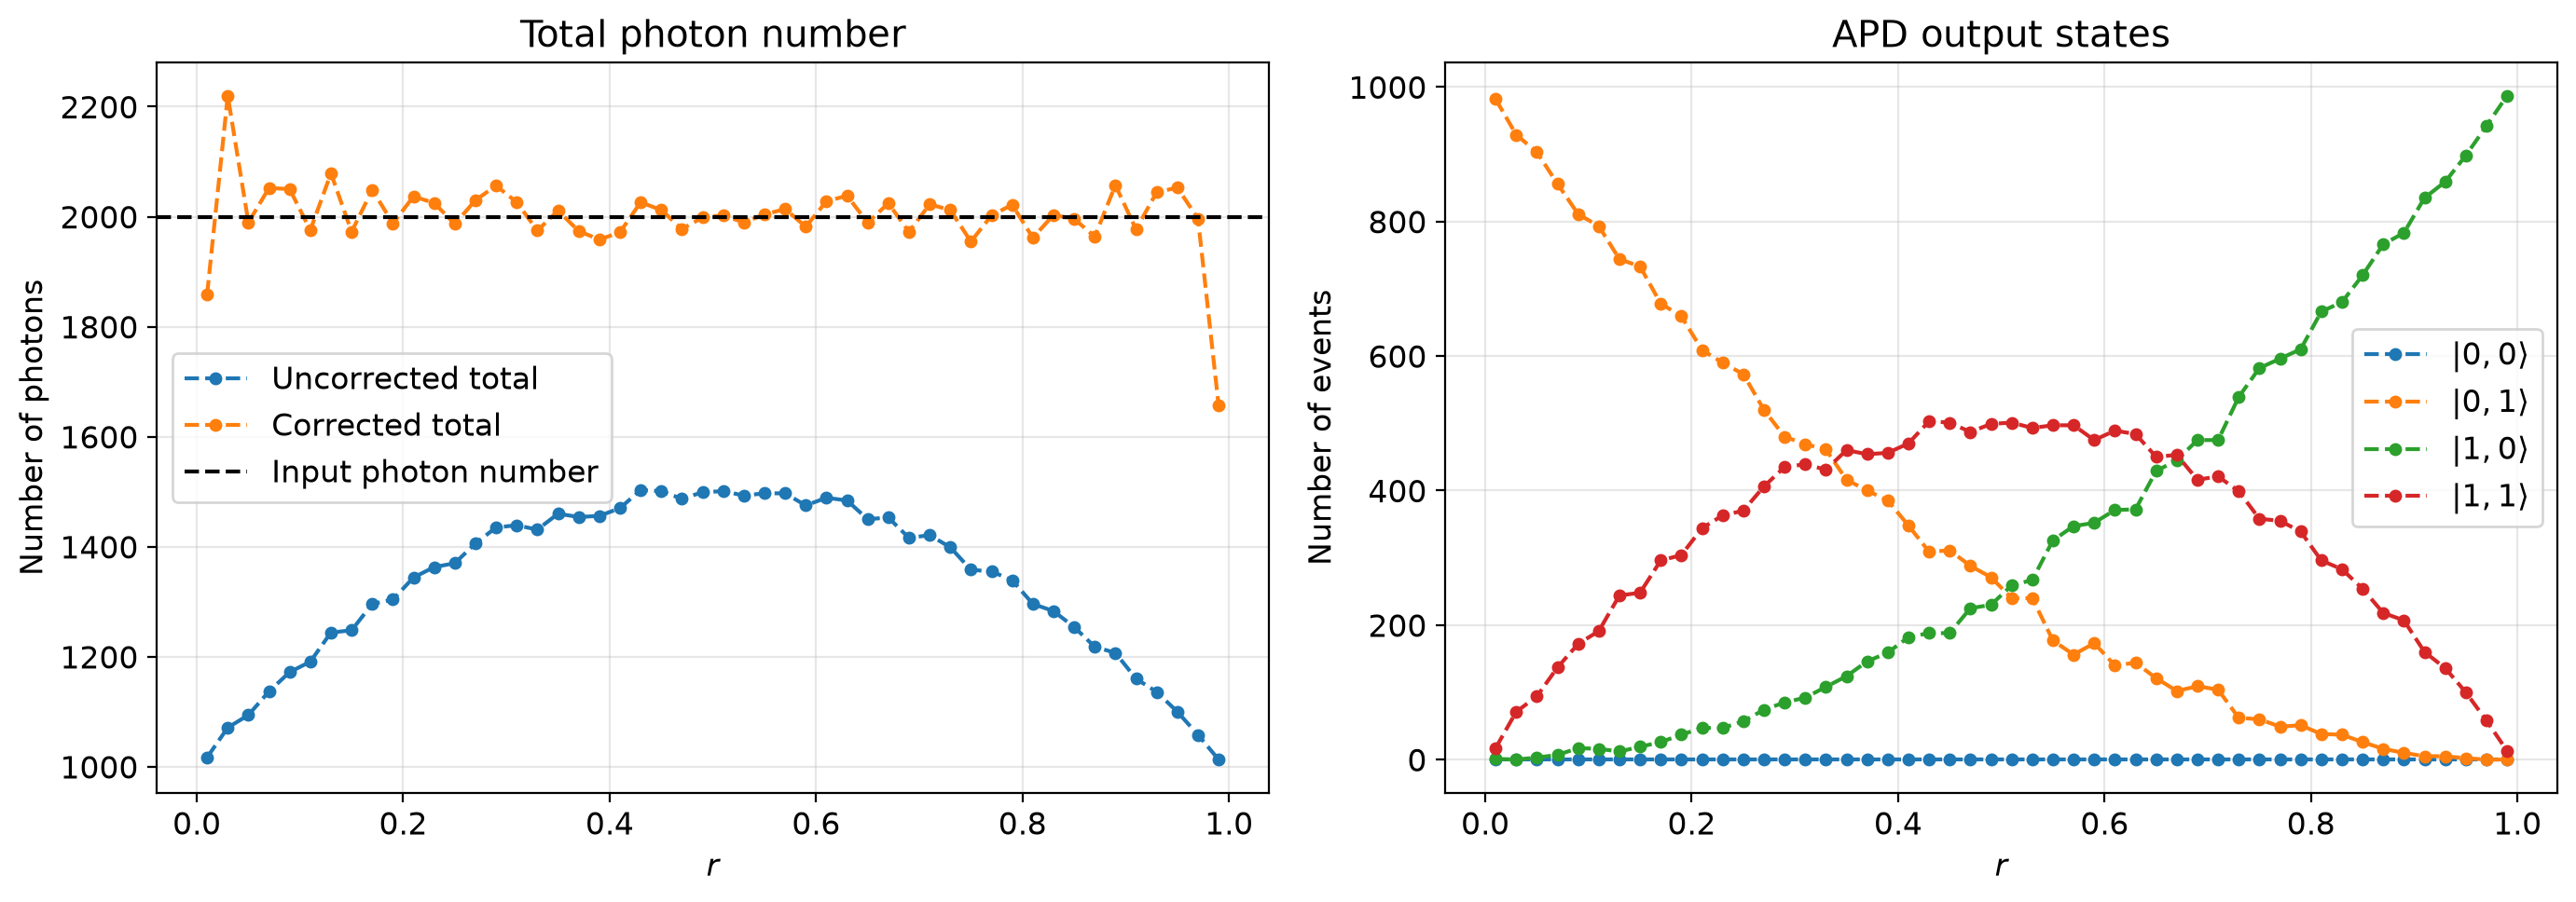

In [10]:
state = pcvl.BasicState('|2,0>')
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    # APD / threshold detectors
    proc.add(0, pcvl.Detector.threshold())
    proc.add(1, pcvl.Detector.threshold())

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # Correction
    M = (t / (2 * r) + r / (2 * t)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
ax1.axhline(
    2 * n_samples,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Input photon number'
)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

As we can see (in the **blue** line) the number of photons measured by an APD is quite lower then the expected number of photons (line --). This is a consequence of not being able to measure $|2,0\rangle$ and confusing it with $|1,0\rangle$ (as we can see on the graph in the right: there are no two photon states, only one photon states that we know should not exist). However by adding the correction factor $M$ we recover the total number of expected photons, as seen in the **orange** line.

Although there are some fluctuation, which may be expected since the correction factor is based on the Coincidence counts which fluctuate in each run and maybe because of numerical uncertanties given that $r$ and $t$ are floating numbers. Remember we are sampling in order to get these results! If we ran this instead of 1000 times 100000 we would certanly get a much smoother result.

We can now even add detector efficiencies and our correction factor becomes:

$$
M = (\frac{\eta_1T}{2\eta_2R} + \frac{\eta_2R}{\eta_12T}) * C
$$

In [11]:
eta1 = 0.9
eta2 = 0.9

### Although we can obviously set different eta's, it is better for the visualization purpose to keep them the same.
### This guarantees that we always have a easy to calculate expected total number counts.
### if they were different as we changed the transmitance the number count would increase.
## this is not a problem!! But just to keep a pretty graph I will keep the efficiencies the same.

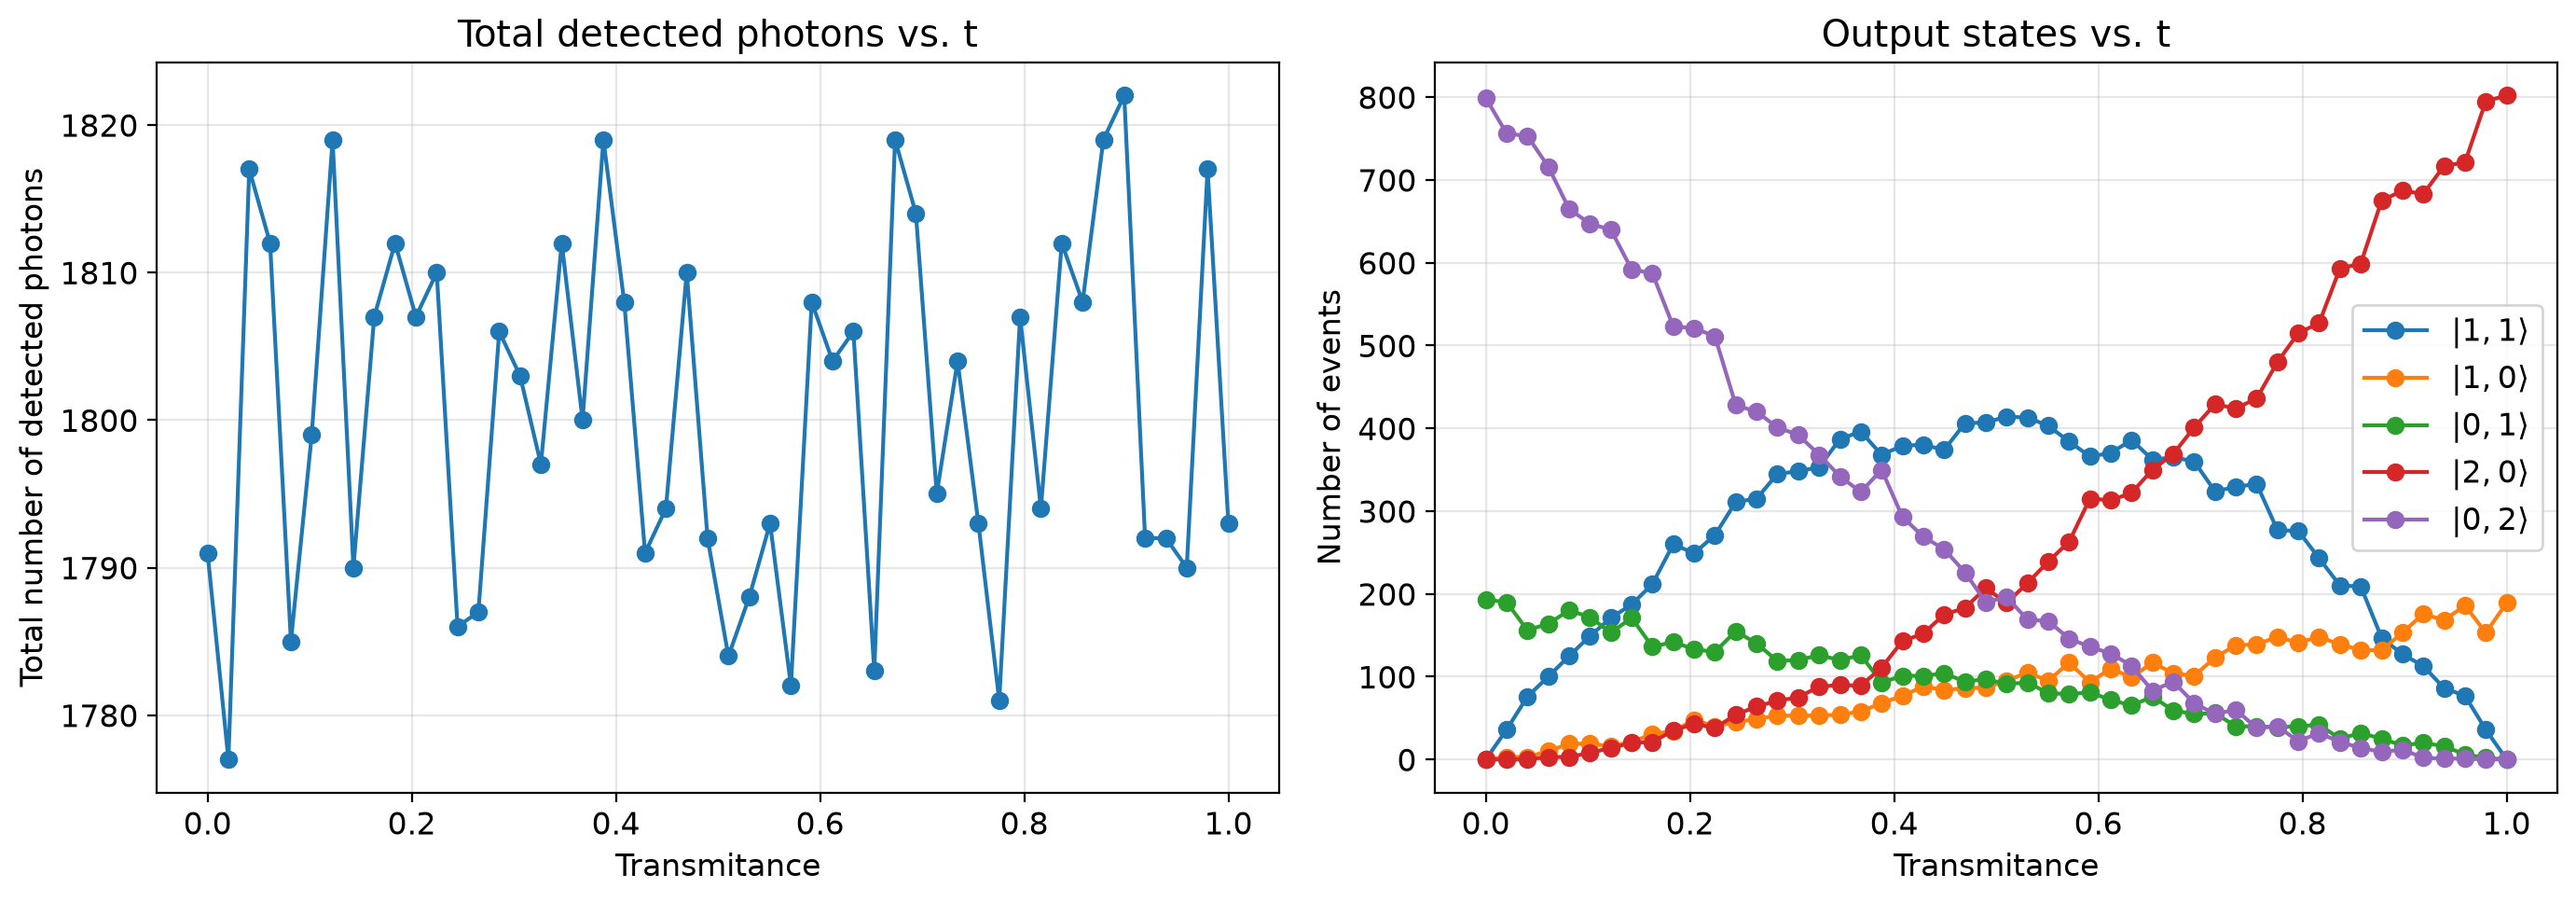

In [12]:
# Beam splitter defined from transmitance
def coincidence(r):
    return pcvl.Circuit(2) // pcvl.BS(pcvl.BS.r_to_theta(r))


# Reflectivity range
rs = np.linspace(0., 1, 50)

# Transmission
ts = 1 - rs

state = pcvl.BasicState('|2,0>')

result = []

n_samples = 1000

# Total number of detected photons for each theta
total_photons = []

for t in ts:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(t),
        noise=pcvl.NoiseModel(brightness=1)
    )

    detector1 = pcvl.Detector.pnr() # PNR
    detector1.efficiency = eta1 # efficiency

    detector2 = pcvl.Detector.pnr() # PNR
    detector2.efficiency = eta2 # efficiency

    proc.add(0, detector1)
    proc.add(1,detector2)

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0,
        '20': 0,
        '02': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

        elif sample == pcvl.BasicState('|2,0>'):
            counts['20'] += 1

        elif sample == pcvl.BasicState('|0,2>'):
            counts['02'] += 1

    result.append(counts)

    # Total number of detected photons for this theta
    N_photons = (
        counts['01']
        + counts['10']
        + 2*counts['11']
        + 2*counts['20']
        + 2*counts['02']
    )

    total_photons.append(N_photons)


# ---------------------------------------------------------
# Extract the individual counts
# ---------------------------------------------------------

n01 = [r['01'] for r in result]
n10 = [r['10'] for r in result]
n11 = [r['11'] for r in result]
n20 = [r['20'] for r in result]
n02 = [r['02'] for r in result]


# ---------------------------------------------------------
# Create two subplots
# ---------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Total number of photons
# ---------------------------------------------------------

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel(r'Transmitance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title('Total detected photons vs. t')

ax1.grid(True)


# ---------------------------------------------------------
# Plot 2: Individual output states
# ---------------------------------------------------------

ax2.plot(
    ts,
    n11,
    marker='o',
    label=r'$|1,1\rangle$'
)

ax2.plot(
    ts,
    n10,
    marker='o',
    label=r'$|1,0\rangle$'
)

ax2.plot(
    ts,
    n01,
    marker='o',
    label=r'$|0,1\rangle$'
)

ax2.plot(
    ts,
    n20,
    marker='o',
    label=r'$|2,0\rangle$'
)

ax2.plot(
    ts,
    n02,
    marker='o',
    label=r'$|0,2\rangle$'
)

ax2.set_xlabel(r'Transmitance')
ax2.set_ylabel('Number of events')
ax2.set_title('Output states vs. t')

ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()

In [13]:
eta1 = 0.9; eta2 = 0.9

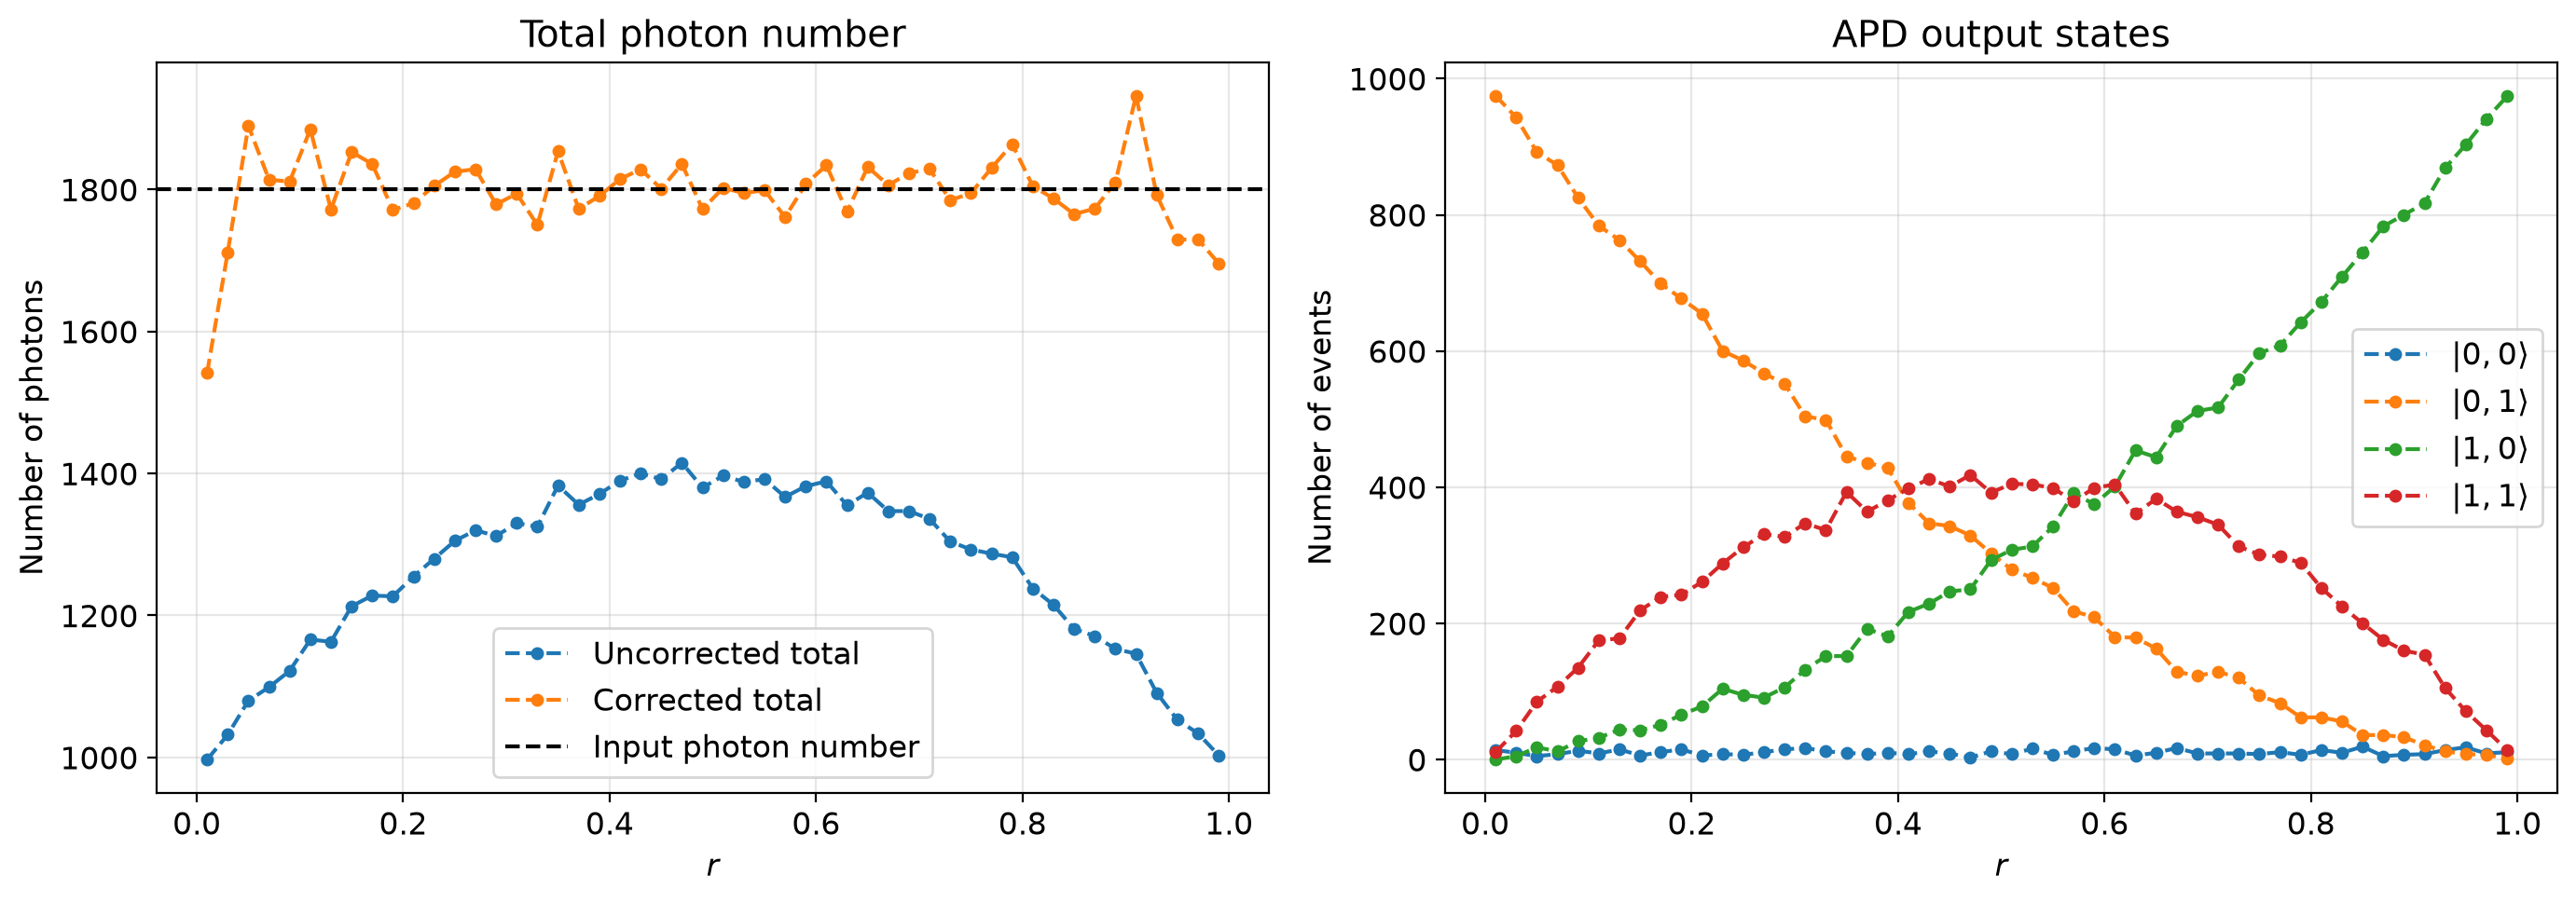

In [14]:
state = pcvl.BasicState('|2,0>')
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)


    detector1 = pcvl.Detector.threshold() # PNR
    detector1.efficiency = eta1 # efficiency
    proc.add(0, detector1)

    detector2= pcvl.Detector.threshold() # PNR
    detector2.efficiency = eta2 # efficiency
    proc.add(1, detector2)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # Correction
    M = ((t*eta1) / (2*eta2 * r) + (eta2*r) / (2*eta1 * t)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
ax1.axhline(
    2 * n_samples*eta1,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Input photon number'
)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

#### the text is still a work in progress...


Great! Works again. We have shown that for our premisses the correction factor works pretty well! However our real problem is a bit different. We do not have such simple states with two photons entering, always indistinguishably and with PNR detectors to compare. But we are slowly getting closer to it. Let's keep progressively working towards a more realistic simulation of our problem.



SPDC is a non-linear process which produces multi-pair emissions, indistinguishable in space and time, from a coherent pump. This state can be described by the state-vector:
$$
|\psi\rangle_{SPDC} = (1 - \lambda^2)\sum_{n = 0}^\infty \lambda^{2n} |n\rangle_s|n\rangle_i
$$
As we can see the number of photons that can be produced goes up to infinity, if it were not for the coeficients, which get smaller and smaller as we increase the number of photons. In general, we are interested in tuning $\lambda$ so that we can favour the production of states $|1\rangle_s|1\rangle_i$ and higher order pairs are small in comparison.

What we do in Idor is physically block half of the incident light, which is equivalent to mathematically tracing out the signals (or idler) photons. We are left with a thermal distribution of light.



We will now assume the thermal light, because of the detector and coherence arguments, has actually a poissonian light statistics. While, SPDC has a poissonian only for pairs with states $|2n,0\rangle$.

In [15]:
import math

def poisson_spdc(mu_pairs: float, n_max: int):
    """
    Effective Poissonian SPDC pair-source model.

    n is the number of generated photon pairs.

    Each pair contributes 2 photons to mode 0:

        n pairs -> |2n,0>

    Therefore

        rho = sum_n P_pair(n) |2n,0><2n,0|

    with

        P_pair(n) = exp(-mu_pairs)
                    * mu_pairs^n / n!
    """

    mu_pairs = float(mu_pairs)

    weights = [
        math.exp(-mu_pairs)
        * mu_pairs**n
        / math.factorial(n)

        for n in range(n_max + 1)
    ]

    # Renormalize truncated distribution
    Z = sum(weights)

    svd = pcvl.SVDistribution()

    for n, w in enumerate(weights):

        p_n = w / Z

        state = pcvl.StateVector(
            pcvl.BasicState([2*n, 0])
        )

        svd[state] = p_n

    return svd

In [16]:
import math
import perceval as pcvl


def poisson_thermal(mu: float, n_max: int):
    """
    Effective Poissonian thermal-light model.

    Mode 0: Poisson-distributed photon number
    Mode 1: vacuum

        rho = sum_n P(n) |n,0><n,0|

    with

        P(n) = exp(-mu) * mu^n / n!
    """

    mu = float(mu)

    weights = [
        math.exp(-mu) * mu**n / math.factorial(n)
        for n in range(n_max + 1)
    ]

    # Renormalize because we truncate the infinite Poisson distribution
    Z = sum(weights)

    svd = pcvl.SVDistribution()

    for n, w in enumerate(weights):

        p_n = w / Z

        state = pcvl.StateVector(
            pcvl.BasicState([n, 0])
        )

        svd[state] = p_n

    return svd

Given this approximation, we will first plot the PNR response to both states and check how their counts change. After this we will do the same with APDs applying our correction and check if the relationship between the total number of photons is still the same. 

Our expectation is that $\frac{\langle \sigma_p\rangle}{\langle \sigma_t \rangle} = 2$, because this tracing out basically removes half the photons. Of course, this is not as trivial for the physical blocking off. 



In [17]:

def run_measurement_pnr(
    source_type,
    lam,
    N_MAX,
    eta1=1.0,
    eta2=1.0,
    n_samples=1000,
    min_detected_photons=1
):
    """
    Run PNR measurement simulation for either thermal or SPDC light.

    Parameters
    ----------
    source_type : str
        "thermal" or "spdc"

    lam : float
        Parameter used in the source definition.

        Thermal:
            passed to poisson_thermal()

        SPDC:
            passed to poisson_spdc()

    N_MAX : int
        Thermal:
            maximum photon number

        SPDC:
            maximum pair number

    eta1, eta2 : float
        Detector efficiencies.

    n_samples : int
        Number of samples.

    min_detected_photons : int
        Minimum detected photon filter.
        Default = 1.

        Use 0 to retain vacuum detection events.

    Returns
    -------
    results : dict
        Dictionary containing all simulation results.
    """

    # ========================================================
    # DEFINE SOURCE
    # ========================================================

    source_type = source_type.lower()

    if source_type == "thermal":

        state = poisson_thermal(
            lam,
            n_max=N_MAX
        )

        MAX_PHOTONS = N_MAX


    elif source_type == "spdc":

        state = poisson_spdc(
            lam,
            n_max=N_MAX
        )

        MAX_PHOTONS = 2 * N_MAX


    else:

        raise ValueError(
            "source_type must be 'thermal' or 'spdc'"
        )


    # ========================================================
    # ALL PHYSICALLY POSSIBLE OUTPUT STATES
    # ========================================================

    physical_states = [
        (n1, n2)
        for n1 in range(MAX_PHOTONS + 1)
        for n2 in range(MAX_PHOTONS + 1)
        if n1 + n2 <= MAX_PHOTONS
    ]


    # ========================================================
    # CONTAINERS
    # ========================================================

    result = []

    total_photons = []
    total_events = []


    # ========================================================
    # RUN SIMULATION
    # ========================================================

    for t in ts:

        # ----------------------------------------------------
        # Processor
        # ----------------------------------------------------

        proc = pcvl.Processor(
            "SLOS",
            coincidence(t),
            noise=pcvl.NoiseModel(brightness=1)
        )


        # ----------------------------------------------------
        # PNR DETECTORS
        # ----------------------------------------------------

        detector1 = pcvl.Detector.pnr()
        detector1.efficiency = eta1

        detector2 = pcvl.Detector.pnr()
        detector2.efficiency = eta2

        proc.add(0, detector1)
        proc.add(1, detector2)


        # ----------------------------------------------------
        # Input state
        # ----------------------------------------------------

        proc.with_input(state)


        # ----------------------------------------------------
        # Detection filter
        # ----------------------------------------------------

        proc.min_detected_photons_filter(
            min_detected_photons
        )


        # ----------------------------------------------------
        # Sampling
        # ----------------------------------------------------

        sampler = pcvl.algorithm.Sampler(proc)

        samples = sampler.samples(
            n_samples
        )['results']


        # ----------------------------------------------------
        # Initialise counters
        # ----------------------------------------------------

        counts = {
            (n1, n2): 0
            for n1, n2 in physical_states
        }


        # ----------------------------------------------------
        # Count sampled states
        # ----------------------------------------------------

        for sample in samples:

            n1 = int(sample[0])
            n2 = int(sample[1])

            key = (n1, n2)

            if key in counts:

                counts[key] += 1

            else:

                print(
                    f"Warning: unexpected state "
                    f"|{n1},{n2}> at t = {t}"
                )


        result.append(counts)


        # ====================================================
        # TOTAL DETECTED PHOTON NUMBER
        # ====================================================

        N_photons = sum(
            (n1 + n2) * counts[(n1, n2)]
            for n1, n2 in physical_states
        )

        total_photons.append(
            N_photons
        )


        # ====================================================
        # TOTAL NUMBER OF EVENTS
        # ====================================================

        total_events.append(
            sum(counts.values())
        )


    # ========================================================
    # CONVERT TO ARRAYS
    # ========================================================

    total_photons = np.array(
        total_photons
    )

    total_events = np.array(
        total_events
    )


    # ========================================================
    # COUNTS FOR EACH INDIVIDUAL FOCK STATE
    # ========================================================

    state_counts = {}

    for n1, n2 in physical_states:

        state_counts[(n1, n2)] = np.array([
            r[(n1, n2)]
            for r in result
        ])


    # ========================================================
    # COUNTS GROUPED BY TOTAL PHOTON NUMBER
    # ========================================================

    photon_number_counts = {
        N: []
        for N in range(MAX_PHOTONS + 1)
    }


    for r in result:

        for N in range(MAX_PHOTONS + 1):

            count_N = sum(
                r[(n1, n2)]
                for n1, n2 in physical_states
                if n1 + n2 == N
            )

            photon_number_counts[N].append(
                count_N
            )


    for N in photon_number_counts:

        photon_number_counts[N] = np.array(
            photon_number_counts[N]
        )


    # ========================================================
    # RETURN RESULTS
    # ========================================================

    results = {
        "source_type": source_type,

        "lam": lam,
        "N_MAX": N_MAX,
        "MAX_PHOTONS": MAX_PHOTONS,

        "eta1": eta1,
        "eta2": eta2,

        "n_samples": n_samples,
        "min_detected_photons": min_detected_photons,

        "physical_states": physical_states,

        "result": result,

        "total_photons": total_photons,
        "total_events": total_events,

        "state_counts": state_counts,
        "photon_number_counts": photon_number_counts
    }

    return results

In [18]:
def plot_measurement_pnr(results):
    """
    Plot PNR measurement results.

    Produces:
        1. Total detected photon number vs transmittance
        2. Number of events for each output Fock state
    """

    source_type = results["source_type"]

    total_photons = results[
        "total_photons"
    ]

    physical_states = results[
        "physical_states"
    ]

    state_counts = results[
        "state_counts"
    ]


    # ========================================================
    # PLOTS
    # ========================================================

    fig, (ax1, ax2) = plt.subplots(
        1,
        2,
        figsize=(15, 6)
    )


    # ========================================================
    # PLOT 1
    # TOTAL DETECTED PHOTON NUMBER
    # ========================================================

    ax1.plot(
        ts,
        total_photons,
        marker='o'
    )

    ax1.set_xlabel(
        'Transmittance'
    )

    ax1.set_ylabel(
        'Total number of detected photons'
    )

    ax1.set_title(
        f'Total detected photons - {source_type}'
    )

    ax1.grid(True)


    # ========================================================
    # PLOT 2
    # INDIVIDUAL OUTPUT FOCK STATES
    # ========================================================

    for n1, n2 in physical_states:

        # Skip vacuum
        if n1 == 0 and n2 == 0:
            continue

        ax2.plot(
            ts,
            state_counts[(n1, n2)],
            marker='o',
            markersize=3,
            label=rf'$|{n1},{n2}\rangle$'
        )


    ax2.set_xlabel(
        'Transmittance'
    )

    ax2.set_ylabel(
        'Number of events'
    )

    ax2.set_title(
        f'PNR output Fock states - {source_type}'
    )

    ax2.grid(True)

    ax2.legend(
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        fontsize=8,
        ncol=2
    )


    plt.tight_layout()

    plt.show()

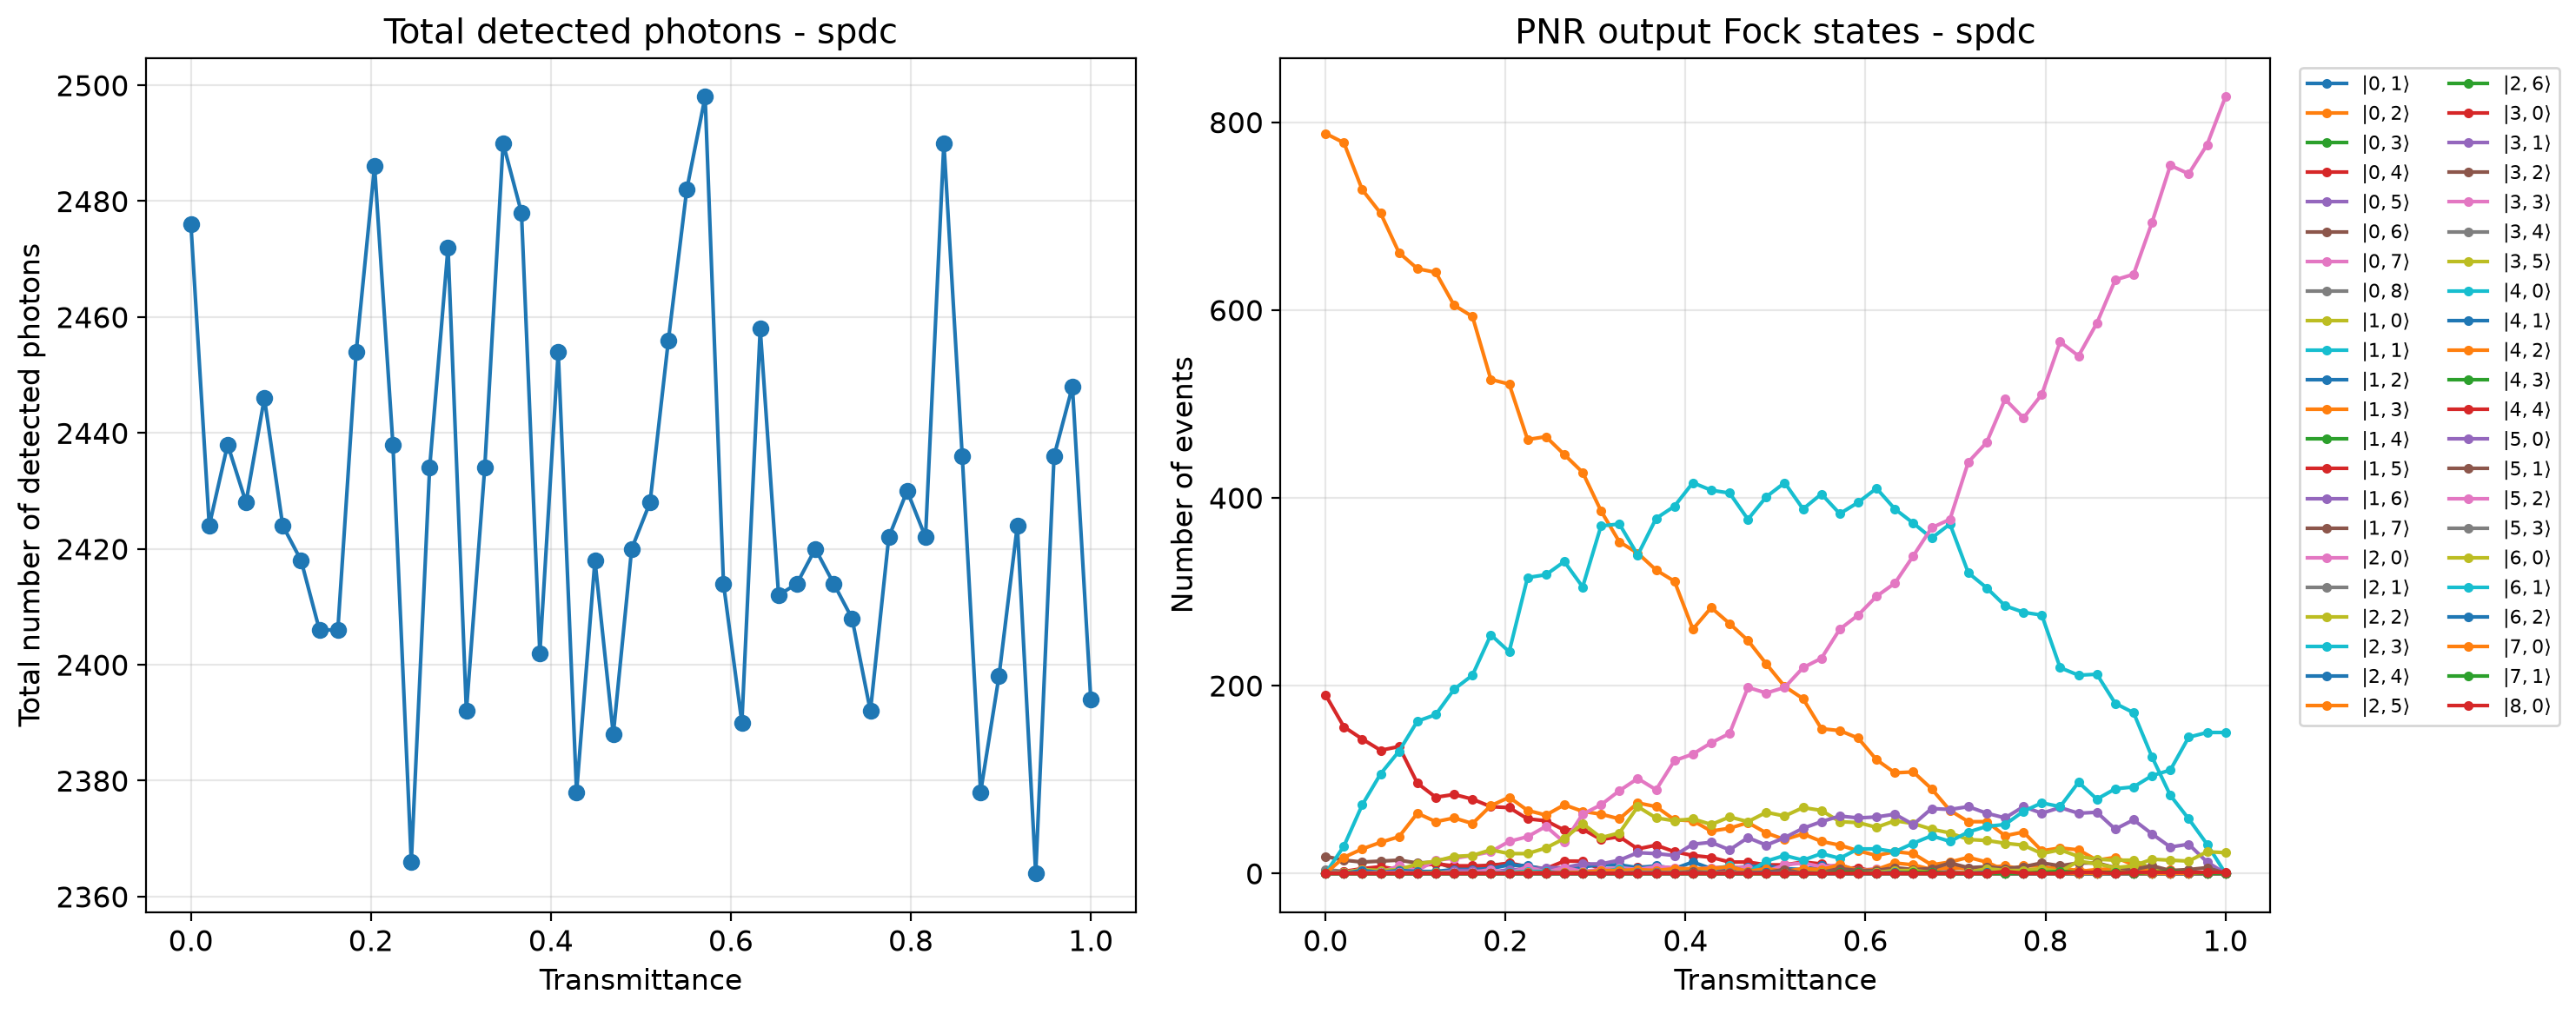

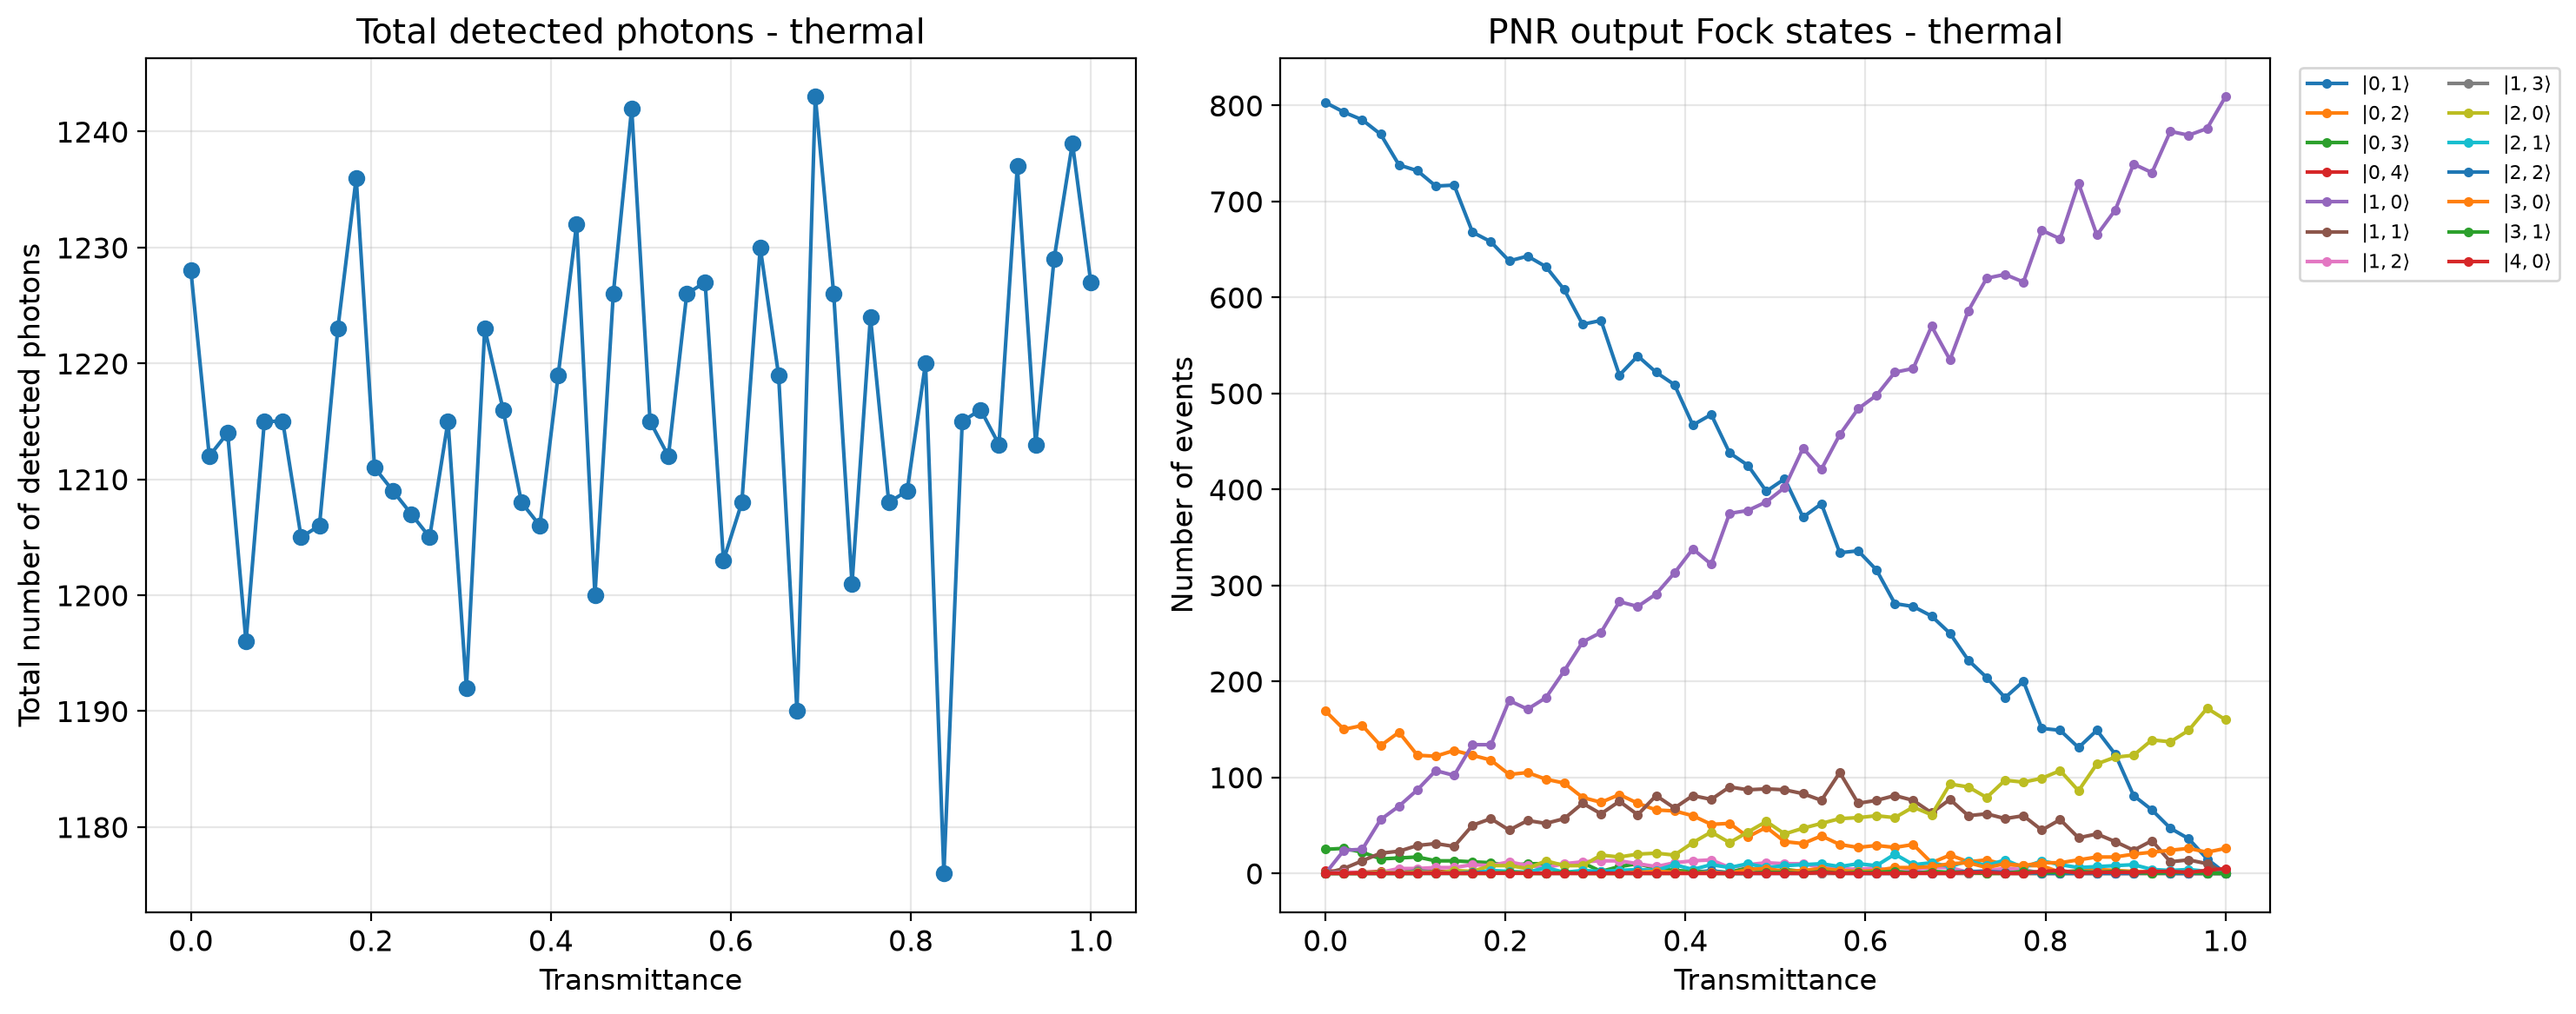

Average SPDC: 2427.96
Average thermal: 1215.74
Avg. SPDC / Avg. thermal = 2.00


In [19]:
spdc_results = run_measurement_pnr(
    source_type="spdc",
    lam=0.4,
    N_MAX=4,
    eta1=1.,
    eta2=1.,
    min_detected_photons=1
)

plot_measurement_pnr(
    spdc_results
)

thermal_results = run_measurement_pnr(
    source_type="thermal",
    lam=0.4,
    N_MAX=4,
    eta1=1.,
    eta2=1.,
    min_detected_photons=1
)

### For this case, since the efficiencies are = 1 we can ignore the 0 photon events. When eff != 1. we need to consider them otherwise the spdc source will be more affected then the thermal one
### prob of detection is \eta^2 for two photons and \eta for one.

plot_measurement_pnr(
    thermal_results
)

avg_spdc = np.mean(
    spdc_results["total_photons"]
)

avg_thermal = np.mean(
    thermal_results["total_photons"]
)
print(f"Average SPDC: {avg_spdc}")
print(f"Average thermal: {avg_thermal}")
print(f'Avg. SPDC / Avg. thermal = {avg_spdc / avg_thermal:.2f}')

Great it works!

----

Now let's repeat this, but for APDs. We know that unfortunately we cannot simply sum the photon counts, becuase of binary (and higher orders) saturation. So what we have to do is compare the total *thermal* (which is poissonian now) count with our total SPDC count + our correction. If the correction still works well for this regime, we expect to see the same value for  $\frac{\langle \sigma_p\rangle}{\langle \sigma_t \rangle}$. 

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import perceval as pcvl


def run_measurement(
    source_type,
    lam,
    N_MAX,
    eta1=1.0,
    eta2=1.0,
    n_samples=1000,
    min_detected_photons=1
):
    """
    Run APD measurement simulation for either thermal or SPDC light.

    Parameters
    ----------
    source_type : str
        "thermal" or "spdc"

    lam : float
        Parameter used in the source definition.

        For thermal:
            interpreted as mu in poisson_thermal()

        For SPDC:
            interpreted as mu_pairs in poisson_spdc()

    N_MAX : int
        Thermal:
            maximum photon number

        SPDC:
            maximum pair number

    eta1, eta2 : float
        Detector efficiencies.

    n_samples : int
        Number of samples.

    min_detected_photons : int
        Minimum detected photon/click filter.
        Default = 1.

        Use 0 to retain vacuum detection events.

    Returns
    -------
    results : dict
        Dictionary containing all simulation results.
    """

    # ========================================================
    # DEFINE SOURCE
    # ========================================================

    source_type = source_type.lower()

    if source_type == "thermal":

        state = poisson_thermal(
            lam,
            n_max=N_MAX
        )

        MAX_PHOTONS = N_MAX


    elif source_type == "spdc":

        state = poisson_spdc(
            lam,
            n_max=N_MAX
        )

        MAX_PHOTONS = 2 * N_MAX


    else:

        raise ValueError(
            "source_type must be 'thermal' or 'spdc'"
        )


    # ========================================================
    # CONTAINERS
    # ========================================================

    result = []

    uncorrected_photons = []
    correction = []
    total_photons = []

    r = np.linspace(0.01,0.99,50)
    # ========================================================
    # RUN SIMULATION
    # ========================================================

    for r in rs:

        # ----------------------------------------------------
        # Processor
        # ----------------------------------------------------

        proc = pcvl.Processor(
            "SLOS",
            coincidence(r),
            noise=pcvl.NoiseModel(brightness=1)
        )


        # ----------------------------------------------------
        # APD / THRESHOLD DETECTORS
        # ----------------------------------------------------

        detector1 = pcvl.Detector.threshold()
        detector1.efficiency = eta1

        detector2 = pcvl.Detector.threshold()
        detector2.efficiency = eta2

        proc.add(0, detector1)
        proc.add(1, detector2)


        # ----------------------------------------------------
        # Input state
        # ----------------------------------------------------

        proc.with_input(state)


        # ----------------------------------------------------
        # Detection filter
        # ----------------------------------------------------

        proc.min_detected_photons_filter(
            min_detected_photons
        )


        # ----------------------------------------------------
        # Sampling
        # ----------------------------------------------------

        sampler = pcvl.algorithm.Sampler(proc)

        samples = sampler.samples(
            n_samples
        )['results']


        # ----------------------------------------------------
        # APD counters
        # ----------------------------------------------------

        counts = {
            '00': 0,
            '01': 0,
            '10': 0,
            '11': 0
        }


        # ----------------------------------------------------
        # Count APD output states
        # ----------------------------------------------------

        for sample in samples:

            if sample == pcvl.BasicState('|0,0>'):

                counts['00'] += 1

            elif sample == pcvl.BasicState('|0,1>'):

                counts['01'] += 1

            elif sample == pcvl.BasicState('|1,0>'):

                counts['10'] += 1

            elif sample == pcvl.BasicState('|1,1>'):

                counts['11'] += 1


        result.append(counts)


        # ====================================================
        # UNCORRECTED APD PHOTON / CLICK NUMBER
        # ====================================================

        N_uncorrected = (
            counts['01']
            + counts['10']
            + 2 * counts['11']
        )

        uncorrected_photons.append(
            N_uncorrected
        )


        # ====================================================
        # SPDC CORRECTION
        # ====================================================

        if source_type == "spdc":

            C = counts['11']

            t = 1-r

            M = (
                t / (2 * r)
                + r / (2 * t)
            ) * C

            correction.append(
                M
            )

            total_photons.append(
                N_uncorrected + M
            )


        # ====================================================
        # THERMAL
        # ====================================================

        elif source_type == "thermal":

            correction.append(
                0.0
            )

            total_photons.append(
                N_uncorrected
            )


    # ========================================================
    # CONVERT TO ARRAYS
    # ========================================================

    uncorrected_photons = np.array(
        uncorrected_photons
    )

    correction = np.array(
        correction
    )

    total_photons = np.array(
        total_photons
    )


    # ========================================================
    # EXTRACT APD STATES
    # ========================================================

    n00 = np.array([
        counts['00']
        for counts in result
    ])

    n01 = np.array([
        counts['01']
        for counts in result
    ])

    n10 = np.array([
        counts['10']
        for counts in result
    ])

    n11 = np.array([
        counts['11']
        for counts in result
    ])


    # ========================================================
    # RETURN ALL RESULTS
    # ========================================================

    results = {
        "source_type": source_type,

        "lam": lam,
        "N_MAX": N_MAX,
        "MAX_PHOTONS": MAX_PHOTONS,

        "eta1": eta1,
        "eta2": eta2,

        "n_samples": n_samples,
        "min_detected_photons": min_detected_photons,

        "result": result,

        "uncorrected_photons": uncorrected_photons,
        "correction": correction,
        "total_photons": total_photons,

        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11
    }

    return results

In [21]:
def plot_measurement(results):
    """
    Plot APD measurement results.

    Produces:
        1. Total photon/click number vs transmittance
        2. Number of events for each APD output state
    """

    source_type = results["source_type"]

    uncorrected_photons = results[
        "uncorrected_photons"
    ]

    total_photons = results[
        "total_photons"
    ]

    n00 = results["n00"]
    n01 = results["n01"]
    n10 = results["n10"]
    n11 = results["n11"]


    # ========================================================
    # PLOTS
    # ========================================================

    fig, (ax1, ax2) = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )


    # ========================================================
    # PLOT 1
    # TOTAL PHOTON / CLICK NUMBER
    # ========================================================

    if source_type == "spdc":

        ax1.plot(
            ts,
            uncorrected_photons,
            'o--',
            linewidth=1.5,
            markersize=4,
            label='Uncorrected total'
        )

        ax1.plot(
            ts,
            total_photons,
            'o--',
            linewidth=1.5,
            markersize=4,
            label='Corrected total'
        )


    elif source_type == "thermal":

        ax1.plot(
            ts,
            total_photons,
            'o--',
            linewidth=1.5,
            markersize=4,
            label='Thermal total'
        )


    ax1.set_xlabel(
        'Transmittance'
    )

    ax1.set_ylabel(
        'Number of photons / clicks'
    )

    ax1.set_title(
        f'Total photon number - {source_type}'
    )

    ax1.grid(
        True,
        alpha=0.3
    )

    ax1.legend()


    # ========================================================
    # PLOT 2
    # APD OUTPUT STATES
    # ========================================================

    ax2.plot(
        ts,
        n00,
        'o--',
        linewidth=1.5,
        markersize=4,
        label=r'$|0,0\rangle$'
    )

    ax2.plot(
        ts,
        n01,
        'o--',
        linewidth=1.5,
        markersize=4,
        label=r'$|0,1\rangle$'
    )

    ax2.plot(
        ts,
        n10,
        'o--',
        linewidth=1.5,
        markersize=4,
        label=r'$|1,0\rangle$'
    )

    ax2.plot(
        ts,
        n11,
        'o--',
        linewidth=1.5,
        markersize=4,
        label=r'$|1,1\rangle$'
    )


    ax2.set_xlabel(
        'Transmittance'
    )

    ax2.set_ylabel(
        'Number of events'
    )

    ax2.set_title(
        f'APD output states - {source_type}'
    )

    ax2.grid(
        True,
        alpha=0.3
    )

    ax2.legend()


    plt.tight_layout()

    plt.show()

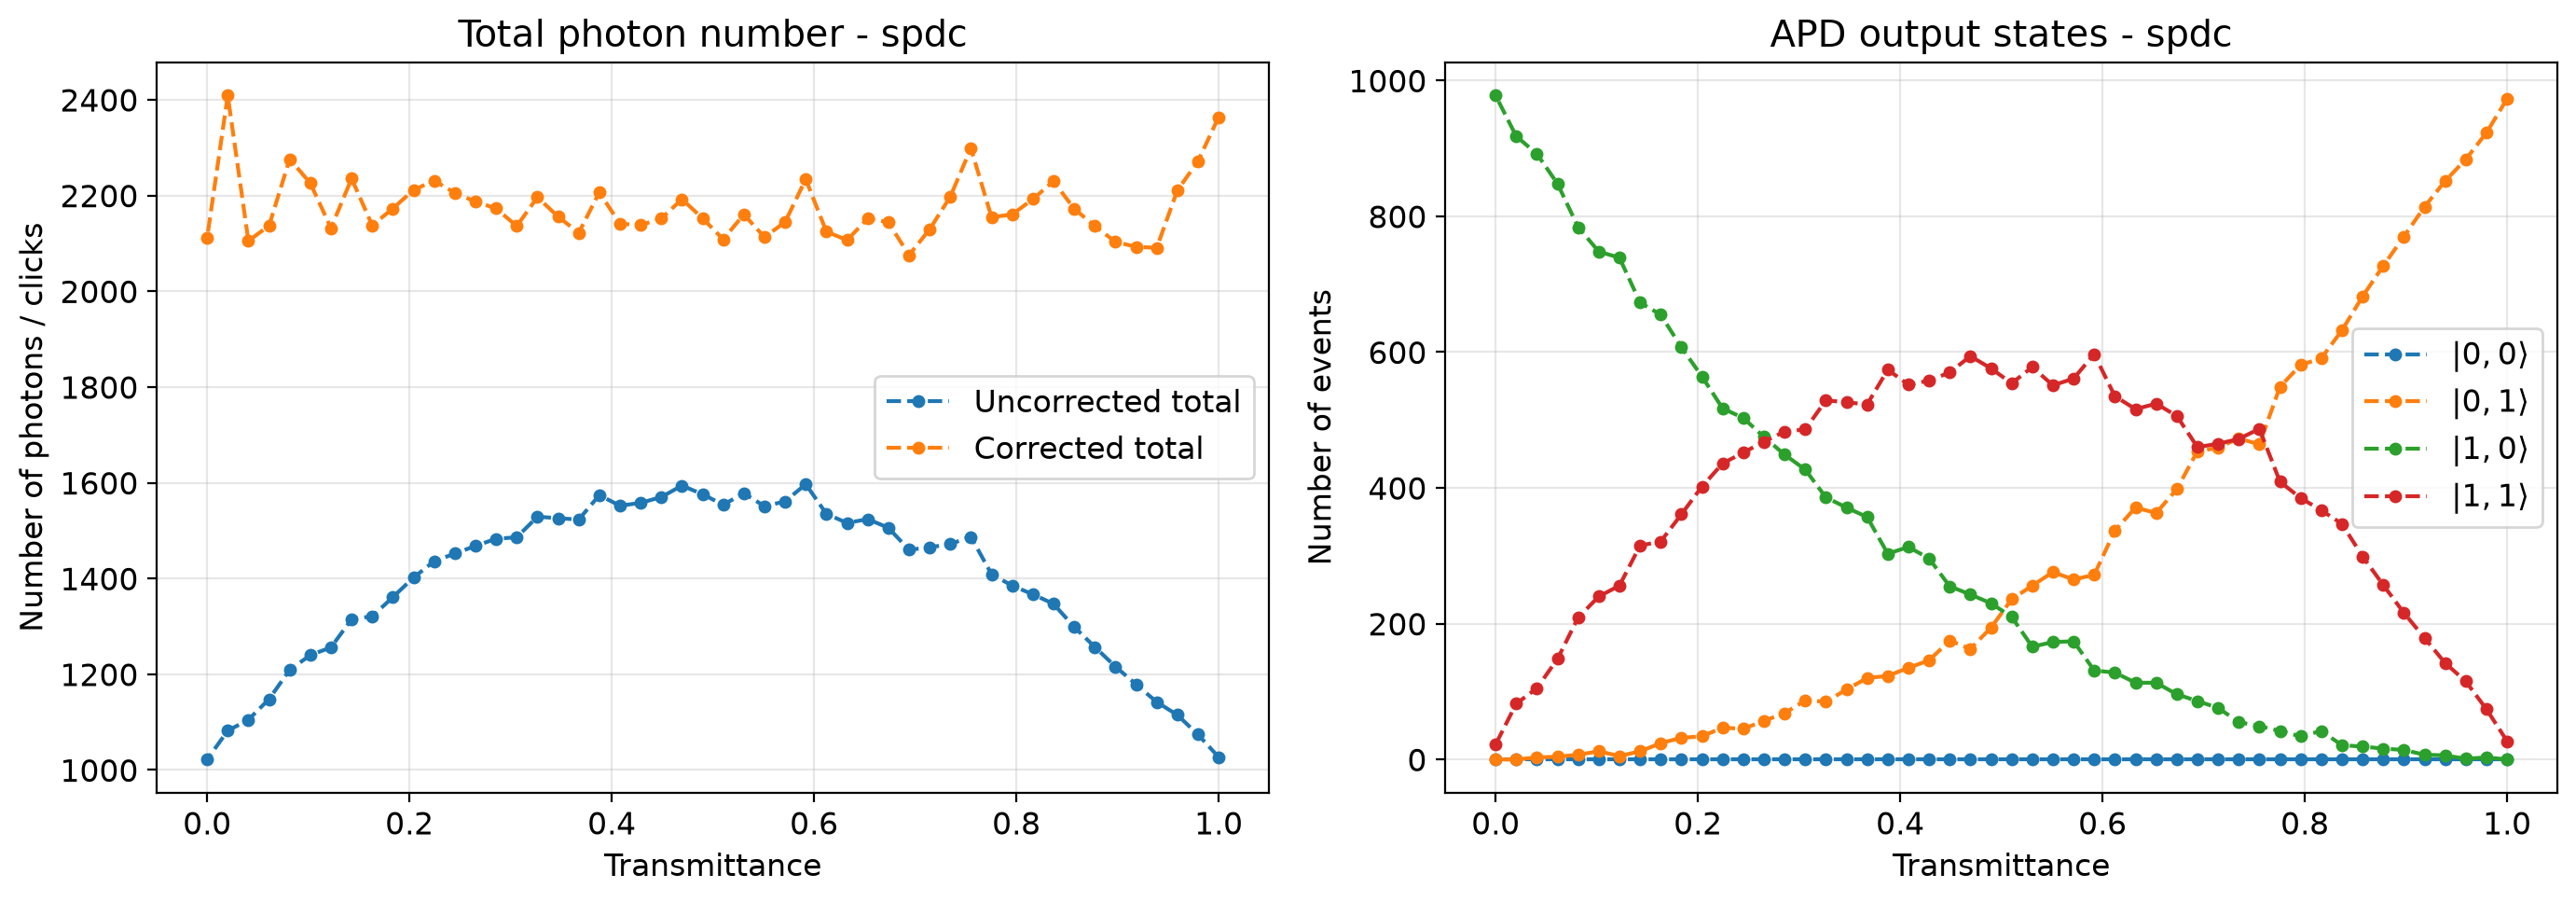

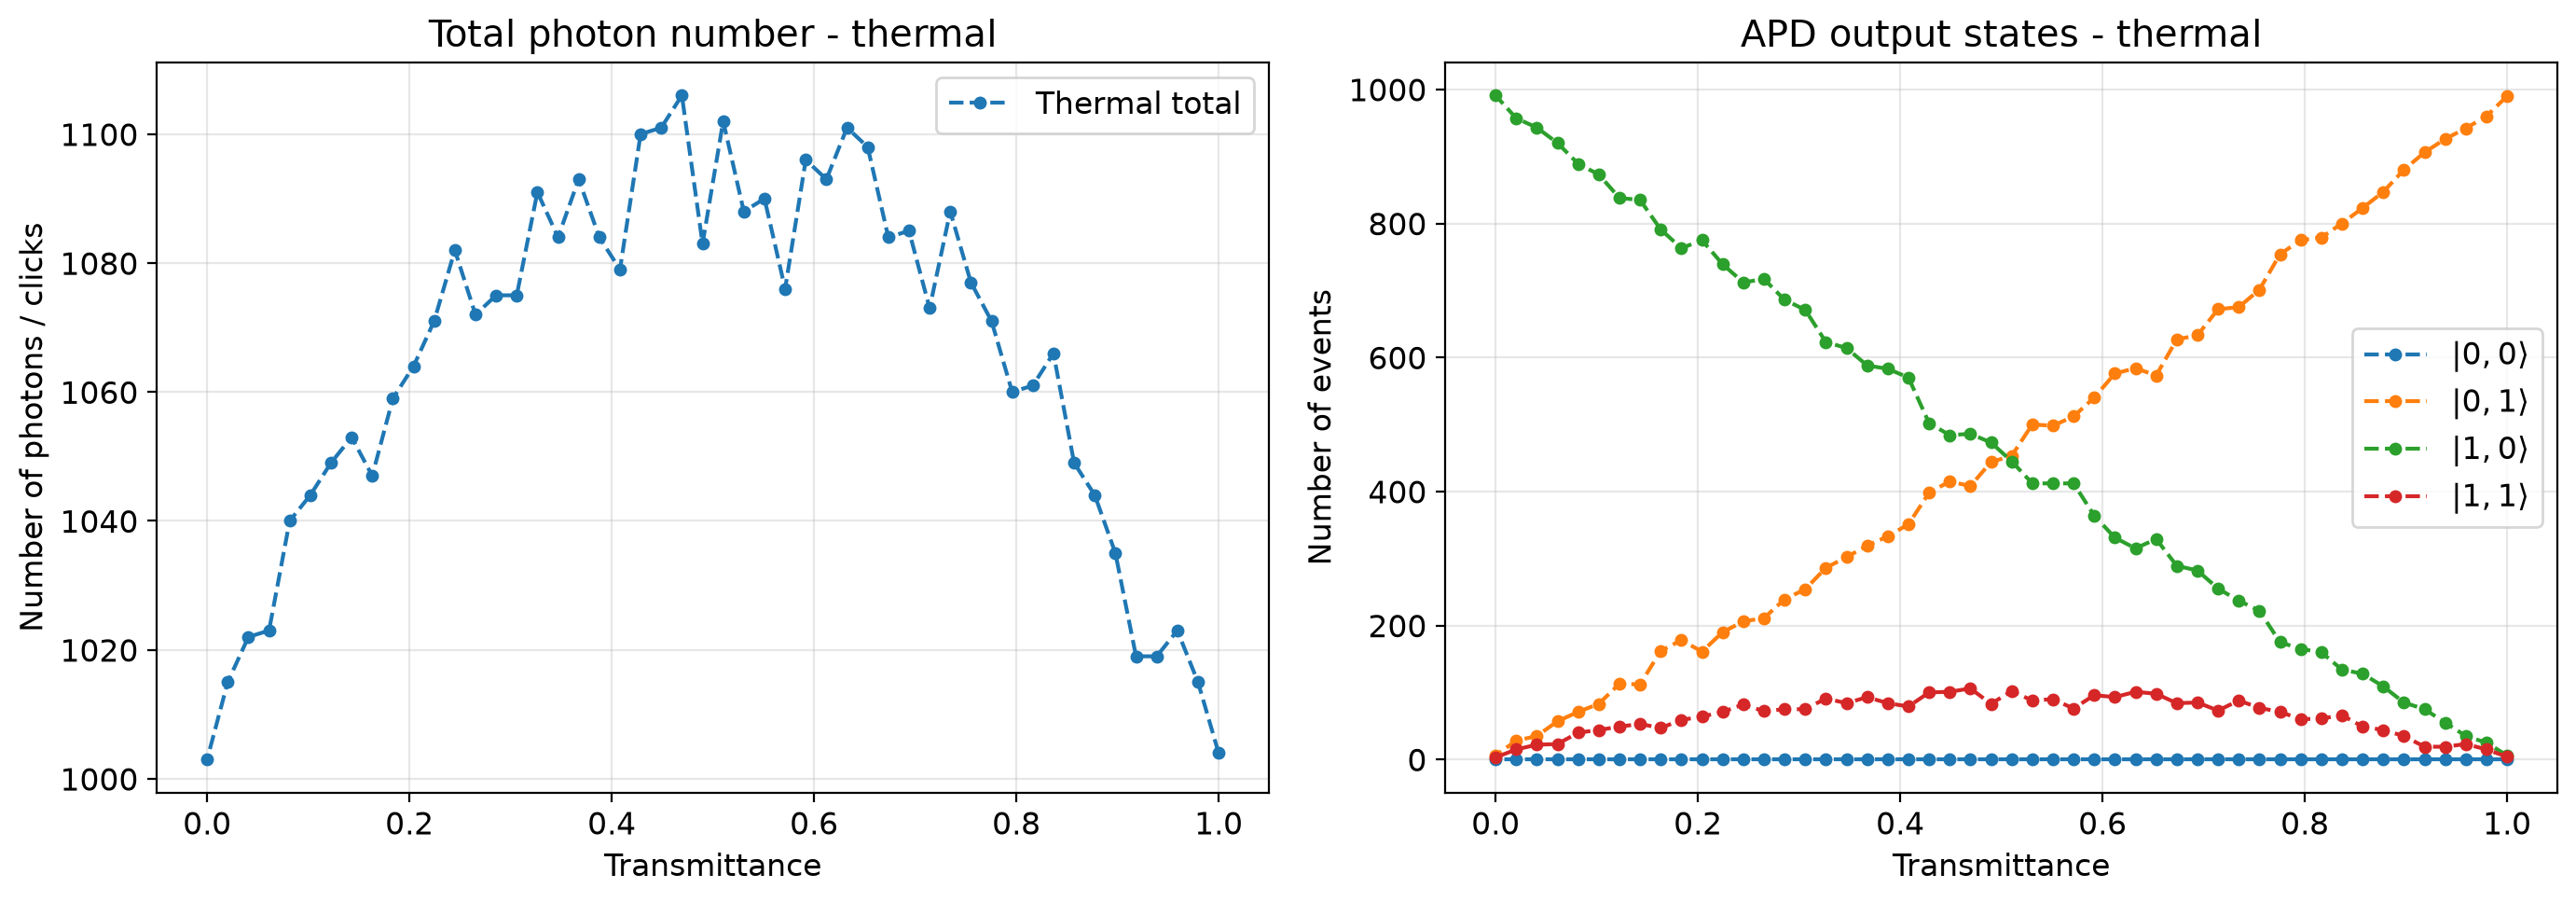

------------------------------------------------------------------------------------------
Average SPDC: 2174.139283175256
Average thermal: 1064.64
Avg. SPDC / Avg. thermal = 2.04


In [27]:
spdc_results = run_measurement(
    source_type="spdc",
    lam=0.4,
    N_MAX=4,
    eta1=1.,
    eta2=1.,
    min_detected_photons=1
)

plot_measurement(
    spdc_results
)

thermal_results = run_measurement(
    source_type="thermal",
    lam=0.4,
    N_MAX=4,
    eta1=1.,
    eta2=1.,
    min_detected_photons=1
)

### For this case, since the efficiencies are = 1 we can ignore the 0 photon events. When eff != 1. we need to consider them otherwise the spdc source will be more affected then the thermal one
### prob of detection is \eta^2 for two photons and \eta for one.

plot_measurement(
    thermal_results
)

avg_spdc = np.mean(
    spdc_results["total_photons"]
)

avg_thermal = np.mean(
    thermal_results["total_photons"]
)

print("---------"*10)
print(f"Average SPDC: {avg_spdc}")
print(f"Average thermal: {avg_thermal}")
print(f'Avg. SPDC / Avg. thermal = {avg_spdc / avg_thermal:.2f}')

For different efficiencies:


Obs.: for the rest of the notebook we used a filter for the minimum detected photons of 1. This means that if we defined 1000 samples our simulation will run 1000 times and ignore everytime that it got a 0. This was done before, because both poissonian light sources (pair and no pair) are equally infested with 0 counts and they would simply add noise to our plots, without really showing us anything interesting. This is not true, however, for when we add $\eta <1$ to our detectors their response varies according to the different light source. What I mean is, for detecting two photons one in each detector the probability is given by $\eta^2$, whereas for a single photon $\eta(1 - \eta)$, where $\eta^2 > \eta(1 - \eta)$, therefore the chance of lossing a photon once we have poorer detectors is bigger when we have pairs arriving, rather then singles. Therefore for SPDC and our whole correction scheme (which is dependent on coincidences) we will notice a worse effect with the worse efficiencies, then we do with the *thermal* light source. While for SPDC a possible $|1,1\rangle$ state will be counted as a $|1,0\rangle$ for example, in our thermal $|1,0\rangle$ state will be lost and discarted by our filtering and counted again until we get a single count. This leads to our $\frac{\langle \sigma_p\rangle}{\langle \sigma_t \rangle}$ decreasing not like we expected. 

You can check this out by simply changing min_detected_photons in any of the functions. You can even see that for before when setting it to zero we just got noisier results, but with the same averaging. 

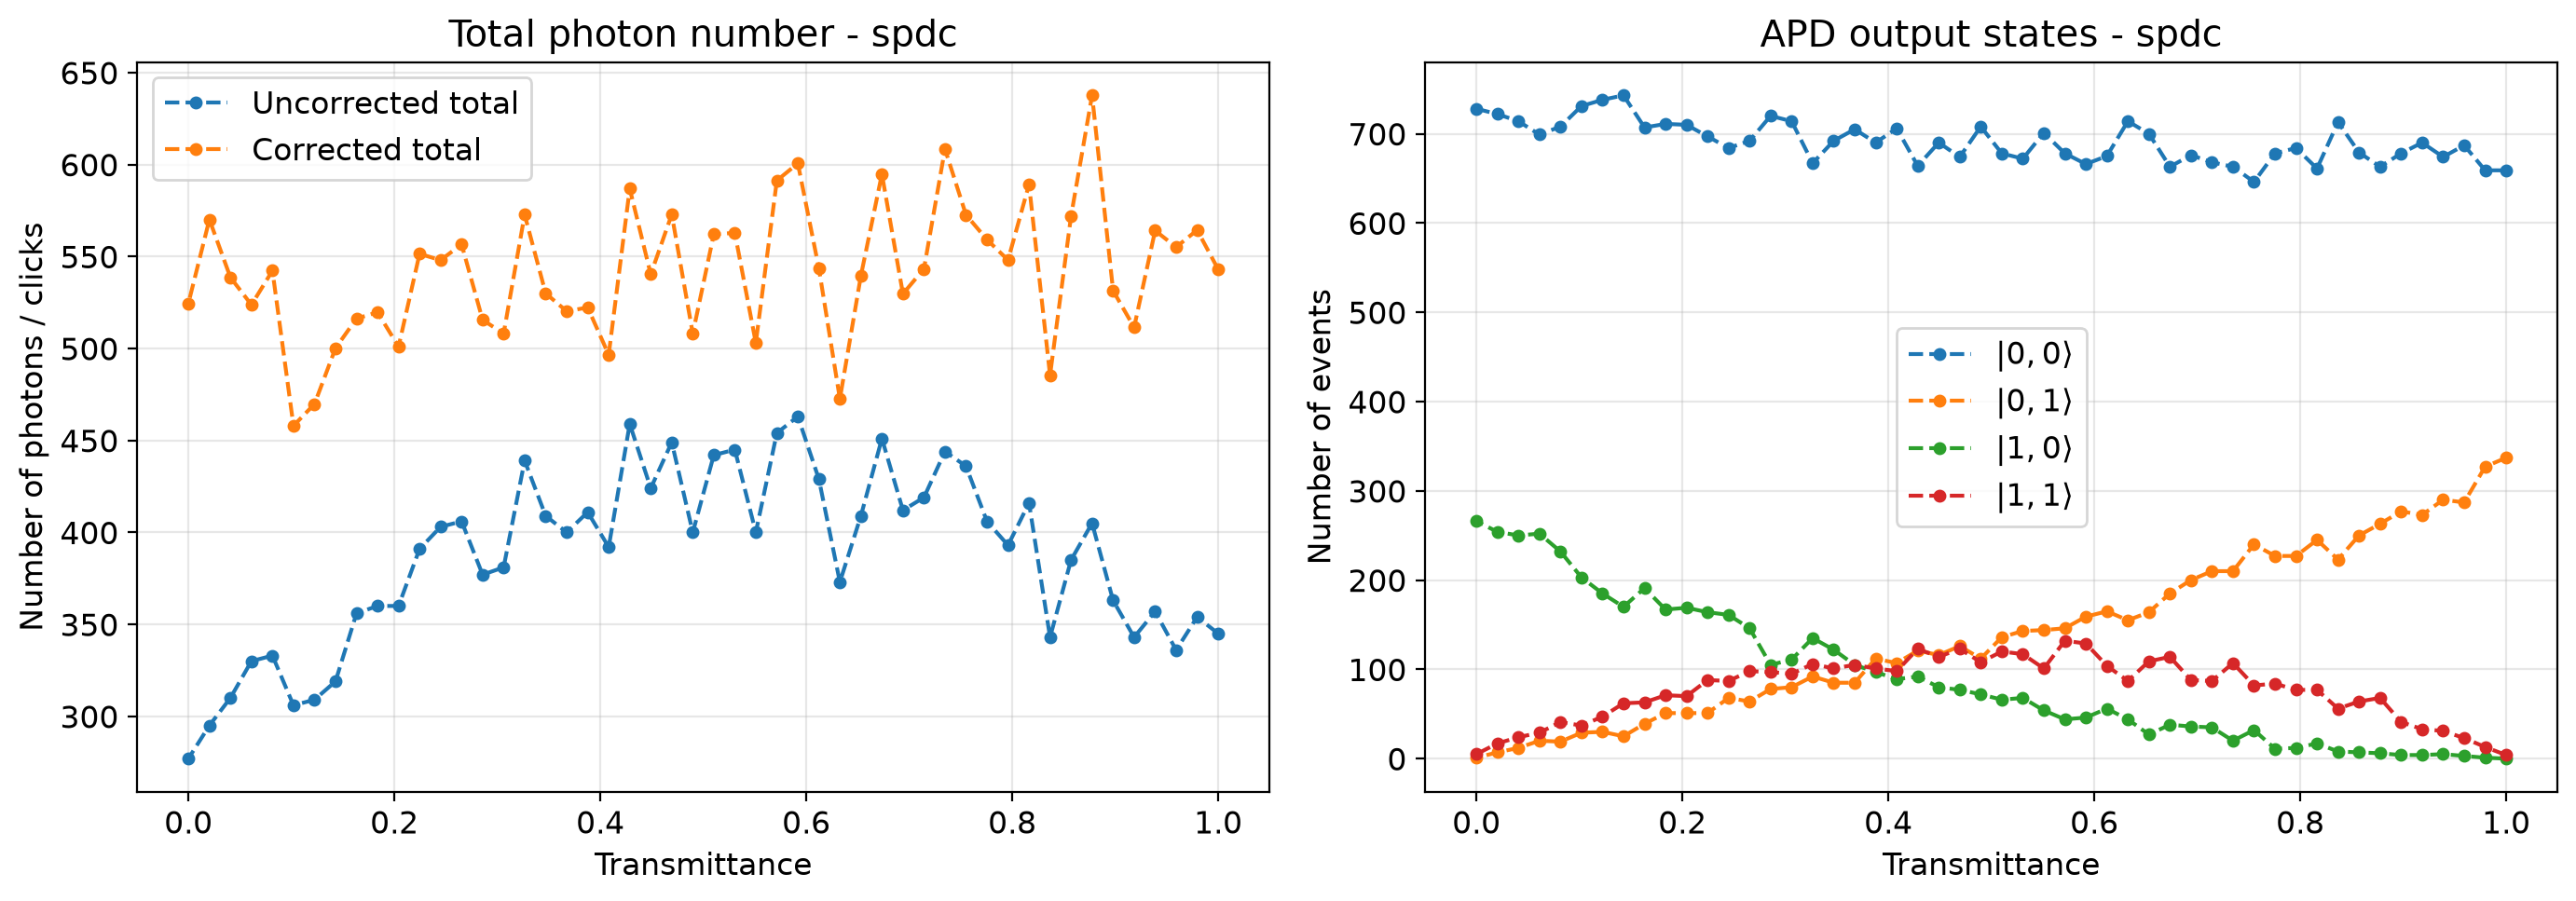

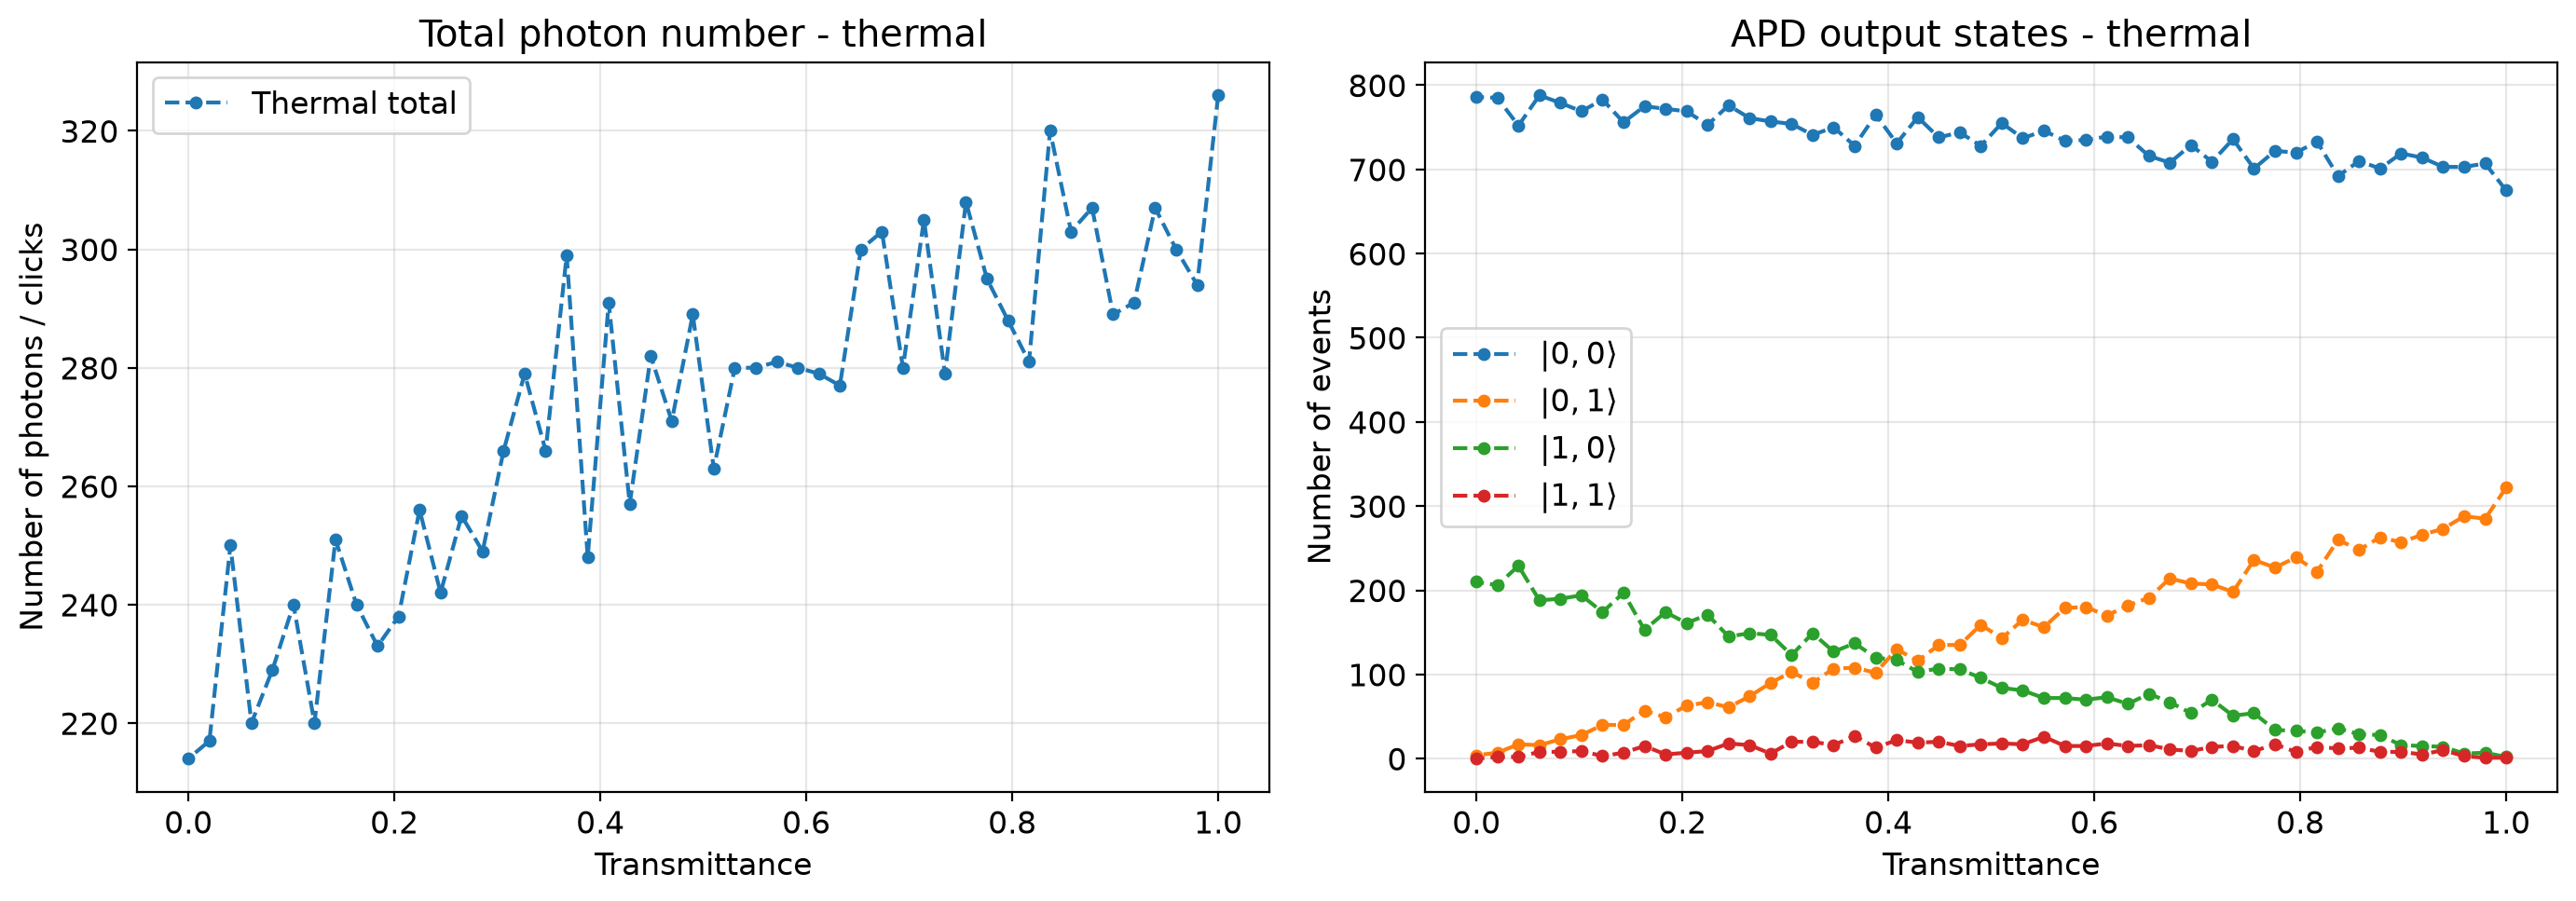

Average SPDC: 541.5817150457732
Average thermal: 272.36
Avg. SPDC / Avg. thermal = 1.99


In [23]:
spdc_results = run_measurement(
    source_type="spdc",
    lam=0.4,
    N_MAX=4,
    eta1=0.6,
    eta2=0.9,
    min_detected_photons=0
)

plot_measurement(
    spdc_results
)

thermal_results = run_measurement(
    source_type="thermal",
    lam=0.4,
    N_MAX=4,
    eta1=0.6,
    eta2=0.9,
    min_detected_photons=0
)

plot_measurement(
    thermal_results
)

avg_spdc = np.mean(
    spdc_results["total_photons"]
)

avg_thermal = np.mean(
    thermal_results["total_photons"]
)
print(f"Average SPDC: {avg_spdc}")
print(f"Average thermal: {avg_thermal}")
print(f'Avg. SPDC / Avg. thermal = {avg_spdc / avg_thermal:.2f}')

Worked again! This shows that the correction factor does well in 

### AI use:
Chat GPT was used to implement parts of the code. A commom use was: write a sketch of the code and send to chat gpt to rewrite in more efficiently and with clear documentation. The functions in the final steps for example were done entirely with GPT, only with my instructions based on the previous code. The writing itself is my own.